# 🎰 Language Models: from counting characters to GPT

### Human Language Technologies 2026-27 · Lab

Today every model plays the same game:

> **Given the characters seen so far, bet on the next character.**

We begin with a classical count-based **n-gram model** and end with a **tiny GPT**. The dataset, the vocabulary, the train/validation split, the evaluation metric and the generation task stay the same throughout:

| Language model | Character n-gram                         | Tiny GPT                                                  |
| -------------- | ---------------------------------------- | --------------------------------------------------------- |
| Unit           | character                                | character                                                 |
| Goal           | predict the next character               | predict the next character                                |
| Context        | the exact last `n-1` characters          | a learned representation of up to `block_size` characters |
| Learning       | count occurrences                        | gradient descent                                          |
| Parameters     | count/probability tables                 | neural-network weights                                    |
| Generation     | sample from next-character probabilities | sample from next-character probabilities                  |

> 🇬🇧 / 🇮🇹 You can choose the corpus: **Tiny Shakespeare** (English) or Dante's **Divina Commedia** (Italian). Pick one at the start and keep it for the whole notebook.

### 🎯 Learning goals

By the end of the notebook you should be able to:

- estimate n-gram probabilities from counts (**maximum likelihood**) and explain why generation is **sampling**;
- evaluate a language model on held-out text with **cross-entropy** and **perplexity**, and explain why smoothing is needed;
- explain why longer n-gram contexts run into a **sparsity wall**;
- map every line of a small GPT implementation onto the **transformer architecture** of the lectures: embeddings, positions, causal multi-head attention, feedforward layers, residual stream, layer norm, language modeling head;
- train it with the same next-token objective and compare it with the n-grams;
- make it fast: **vectorised attention**, **optimised attention kernels** and the **KV cache** (Exercise).

> **Important:** we deliberately use **characters** as tokens, so that tokenization stays transparent. Modern LLMs use subword tokens (BPE, Lecture 02), but the language-modeling objective is exactly the same.


> 🔍 **Lectures and reading.** The n-gram half of this lab follows Lecture 04 (_N-gram language models_) and Lecture 05 (_Smoothing and entropy_), SLP Ch. 3. The neural half follows Lecture 13 (_Neural networks_, SLP Ch. 6) and Lectures 14–15 (_Transformers_, SLP Ch. 7: attention §7.1, transformer blocks §7.2, the matrix form §7.3, embeddings and positions §7.4, the language modeling head §7.5, decoding §7.6, pretraining §7.7, the KV cache §7.8). The companion notebooks of Lectures 04, 05 and 14 compute the same quantities by hand on toy examples; here we scale them up to a real corpus and to PyTorch.


## 🏠 House rules

For a sequence of characters $x_1,\dots,x_T$, a language model assigns probabilities with the **chain rule**:

$$
P(x_1,\ldots,x_T)=\prod_{t=1}^{T}P(x_t\mid x_{<t}).
$$

The whole notebook is about one question:

> How should we estimate $P(x_t\mid x_{<t})$?

An n-gram model answers with **counts from an exact short context** (the Markov assumption of Lecture 04). GPT answers with a **learned neural representation of a longer context**.

> 🔍 **Notation.** The slides write words $w_{1:n}$ and the history $w_{<n}$; here the tokens are characters, so we write $x_t$. We also do not add the `<s>` and `</s>` symbols of Lecture 04: the corpus is one long stream of characters, and the newline `\n` is a character like any other.


# 🧪 0. Setup

In Colab, choose **Runtime → Change runtime type → GPU** if you can. The n-gram half is essentially instantaneous; the GPT half is deliberately small enough to remain usable on CPU (with fewer training steps).


In [1]:
# 🧪 Setup (just run it): imports the libraries used in the notebook and fixes the random seeds
import copy
import math
import random
import time
import urllib.request
from collections import Counter, defaultdict
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn

SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = (
    "cuda" if torch.cuda.is_available() else "cpu"
)  # every tensor and model will live on this device
print("PyTorch:", torch.__version__)
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


# 🎭 1. A corpus and a casino

You can choose **one of two corpora**. Everything that follows (count-based and neural models) uses the one you pick.

|          | 🇬🇧 Tiny Shakespeare          | 🇮🇹 Divina Commedia                                              |
| -------- | ---------------------------- | --------------------------------------------------------------- |
| Author   | William Shakespeare          | Dante Alighieri                                                 |
| Language | Early Modern English         | 14th-century Italian (Tuscan)                                   |
| Content  | extracts from several plays  | the whole poem: _Inferno_, _Purgatorio_, _Paradiso_ (100 canti) |
| Form     | dialogue: `SPEAKER:` + lines | poetry in _terza rima_: tercets of hendecasyllables             |
| Size     | ≈ 1.1 M characters           | ≈ 0.54 M characters                                             |

Every distinct character (letters, accented letters, punctuation, spaces and newlines) is a token. This gives us a small, completely inspectable vocabulary.

👉 **Choose the corpus in the next cell, then run it.** If you change your mind later, re-run the notebook from that cell onwards: the vocabulary, the split and all the models depend on the corpus.


In [2]:
# Choose your corpus
DATASET = "Dante"
# DATASET = "Shakespeare"

SOURCES = {
    "Shakespeare": {
        "name": "Tiny Shakespeare",
        "urls": [
            "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt",
        ],
    },
    "Dante": {
        "name": "Divina Commedia (Dante Alighieri)",
        "urls": [
            # Clean plain text of the whole poem (100 canti, one "CANTO ..." header per canto)
            "https://raw.githubusercontent.com/DanieleVeri/deep_comedy/master/divina_commedia.txt",
            # Fallback: Project Gutenberg eBook #1012 (licence header/footer are stripped below)
            "https://www.gutenberg.org/cache/epub/1012/pg1012.txt",
        ],
    },
}


def strip_gutenberg(raw):
    # Keep only the text between the Project Gutenberg START/END markers
    start = raw.find("*** START")
    end = raw.find("*** END")
    if start != -1 and end != -1:
        raw = raw[raw.find("\n", start) + 1 : end]
    return raw.strip() + "\n"


def download_corpus(choice):
    # Try the sources in order; return the whole corpus as one Python string
    info = SOURCES[choice]
    for url in info["urls"]:
        try:
            raw = urllib.request.urlopen(url, timeout=15).read().decode("utf-8-sig")
        except Exception as e:
            print(f"Could not download {url} ({e}); trying next source...")
            continue
        if "gutenberg.org" in url:
            raw = strip_gutenberg(raw)
        raw = raw.replace("\r\n", "\n")
        print(f"Downloaded {info['name']} from {url}")
        return raw
    raise RuntimeError(f"All download sources failed for {info['name']}.")


text = download_corpus(DATASET)

print(f"Characters: {len(text):,}")
print(text[:700])

Downloaded Divina Commedia (Dante Alighieri) from https://raw.githubusercontent.com/DanieleVeri/deep_comedy/master/divina_commedia.txt
Characters: 535,473
CANTO PRIMO

  Nel mezzo del cammin di nostra vita
mi ritrovai per una selva oscura
ché la diritta via era smarrita.
  Ah quanto a dir qual era è cosa dura
esta selva selvaggia e aspra e forte
che nel pensier rinova la paura!
  Tant'è amara che poco è piú morte;
ma per trattar del ben ch'io vi trovai,
dirò dell'altre cose ch'i' v'ho scorte.
  Io non so ben ridir com'io v'entrai,
tant'era pieno di sonno a quel punto
che la verace via abbandonai.
  Ma poi ch'i' fui al piè d'un colle giunto,
là dove terminava quella valle
che m'avea di paura il cor compunto,
  guardai in alto, e vidi le sue spalle
vestite già de' raggi del pianeta
che mena dritto altrui per ogni calle.
  Allor fu la paura un po


### 🎲 PLACE YOUR BETS #1

Before running the next cell:

1. How many distinct characters do you expect?
2. Is uppercase `A` the same token as lowercase `a`?
3. After the character `t`, which character do you expect to have the highest probability?
4. _Dante only:_ which letters of the English alphabet do you expect **not** to appear at all? And which accented letters will show up?


### 🔤 The vocabulary and the tokenizer

The next cell builds the whole "tokenizer" of this lab in four lines. The vocabulary is the sorted set of characters; `stoi` (_string to integer_) gives each character an id, `itos` goes back. `encode` turns a string into a list of ids, `decode` does the opposite. Models only ever see the ids.


In [3]:
chars = sorted(set(text))  # the vocabulary V: every distinct character of the corpus
vocab_size = len(chars)  # |V|
stoi = {ch: i for i, ch in enumerate(chars)}  # character -> id
itos = {i: ch for ch, i in stoi.items()}  # id -> character


def encode(s):
    return [stoi[c] for c in s]  # "ab" -> [id of a, id of b]


def decode(ids):
    return "".join(itos[i] for i in ids)  # [ids] -> string


print("Vocabulary size:", vocab_size)
print("Vocabulary:")
print(repr("".join(chars)))
print(
    "encode('amor') =", encode("amor"), " decode(...) =", repr(decode(encode("amor")))
)

Vocabulary size: 77
Vocabulary:
"\n !'(),-.:;?ABCDEFGHIJLMNOPQRSTUVZ[]abcdefghijlmnopqrstuvxyz«»ÀÈÏàèéëìíïòúüý…"
encode('amor') = [36, 47, 49, 52]  decode(...) = 'amor'


## 🚫👀 1.1 Train/validation split: no peeking behind the curtain

We split the text **once** and reuse exactly the same split for every model: the first 90% for training, the last 10% for validation.

Training fit tells us how well a model explains data it has already seen; validation fit tells us how well it predicts held-out text.

> 🔍 **Training, development and test sets (Lecture 04).** Our _validation_ set plays the role of the **development set** of the slides: we use it to compare models and choose settings. A careful experiment would also keep a **test set**, used only once at the very end. We skip it to keep the lab short, so our validation numbers are slightly optimistic.


In [4]:
data = encode(text)  # the whole corpus as a list of ids
cut = int(0.90 * len(data))
train_ids = data[:cut]  # the first 90%: counts (n-grams) and gradient descent (GPT)
val_ids = data[cut:]  # the last 10%: held-out evaluation only

print(f"Train characters:      {len(train_ids):}")
print(f"Validation characters:  {len(val_ids):}")
print("Validation starts with:")
print(repr(decode(val_ids[:180])))

Train characters:      481925
Validation characters:  53548
Validation starts with:
"e vien quel ch'ei pensa».\n  Cosí Beatrice; e quelle anime liete\nsi fero spere sopra fissi poli,\nfiammando, volte, a guisa di comete.\n  E come cerchi in tempra d'orïoli\nsi giran sí,"


# 📊 2. Count it, normalize it, generate it

## 👴 2.1 The bigram model: GPT's tiny ancestor

A character bigram model assumes the next character depends only on the previous character (the **Markov assumption**):

$$
P(x_t\mid x_{<t}) \approx P(x_t\mid x_{t-1}).
$$

**Maximum likelihood estimation** is just counting (Lecture 04):

$$
P(b\mid a)=\frac{C(a\,b)}{C(a)}.
$$

No neural network. No optimizer. No gradient descent. Just counting.

The function `build_ngram_table` slides over the training ids and, for every position, records which token followed which context of `order-1` tokens. The result is a dictionary `context tuple -> Counter of next-token ids`: exactly the count table of the slides, stored sparsely (only the pairs that occur). `show_next_chars` prints one row of the table, normalized into probabilities.


In [5]:
def build_ngram_table(ids, order=2):
    # Map a context tuple to counts of next-token IDs.
    #   order=1: unigram (empty context), order=2: bigram, order=3: trigram, ...
    assert order >= 1
    history = order - 1  # n-1 tokens of context
    table = defaultdict(Counter)  # table[context][next_token] = C(context next_token)
    if history == 0:
        for tok in ids:
            table[()][tok] += 1
    else:
        for i in range(history, len(ids)):
            ctx = tuple(ids[i - history : i])  # the exact n-1 previous tokens
            table[ctx][ids[i]] += 1  # count the token that followed them
    return table


bigram_table = build_ngram_table(train_ids, order=2)


def show_next_chars(context_text, table, n=12):
    # One row of the table: the most frequent next characters after context_text, with their MLE probability
    ctx = tuple(encode(context_text))
    counts = table.get(ctx, Counter())
    total = sum(counts.values())  # C(context)
    rows = []
    for tok, count in counts.most_common(n):
        rows.append((
            repr(itos[tok]),
            count,
            count / total,
        ))  # C(context b) / C(context)
    return pd.DataFrame(rows, columns=["next_char", "count", "MLE_probability"])


show_next_chars("t", bigram_table)

,next_char,count,MLE_probability
0,'o',3800,0.189130
1,'e',3638,0.181067
2,'a',3462,0.172307
3,'r',2815,0.140106
4,'i',2322,0.115568
5,'t',2139,0.106460
6,'u',1394,0.069381
7,"""'""",185,0.009208
8,'à',115,0.005724
9,'ú',61,0.003036


### 🗺️ Visualise the map

The bigram model is a $|V| \times |V|$ table of probabilities: row $a$ is the distribution $P(\cdot \mid a)$ of the character that follows $a$. The heatmap below shows the 30 most frequent characters (`␣` is the space, `\n` the newline). Each full row sums to 1 over the whole vocabulary; we only see the 30 most frequent columns. Look for:

- the dark column of `␣`: after the end of a word comes a space;
- vowels following consonants and vice versa;
- rows with a single dark cell: an (almost) deterministic next character (`q`!).


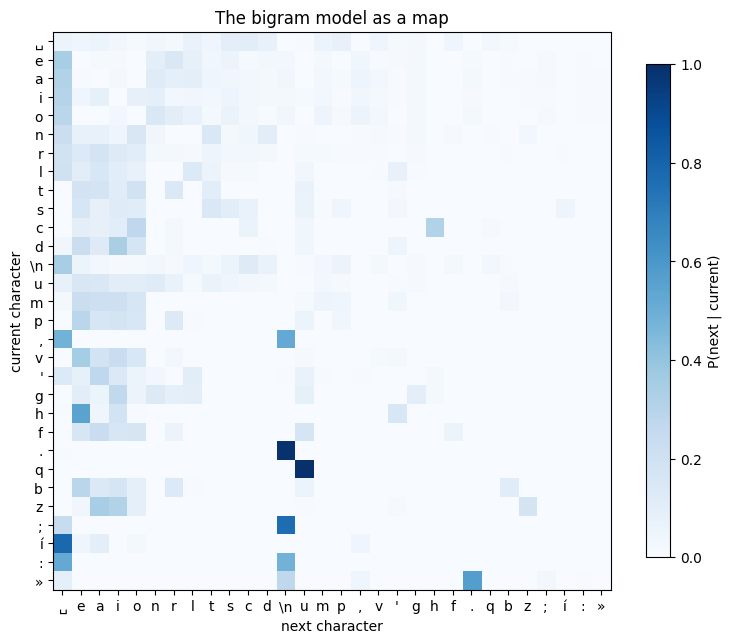

In [6]:
# The bigram "map": P(next char | current char) for the 30 most frequent characters
top = [tok for tok, _ in Counter(train_ids).most_common(30)]
P = np.zeros((len(top), len(top)))
for i, a in enumerate(top):
    counts = bigram_table[(a,)]
    total = sum(counts.values())  # C(a): all the bigrams that start with a
    for j, b in enumerate(top):
        P[i, j] = counts[b] / total  # MLE: C(a b) / C(a)

labels = ["␣" if itos[t] == " " else repr(itos[t])[1:-1] for t in top]
plt.figure(figsize=(9, 8))
plt.imshow(P, cmap="Blues")
plt.colorbar(label="P(next | current)", shrink=0.8)
plt.xticks(range(len(top)), labels)
plt.yticks(range(len(top)), labels)
plt.xlabel("next character")
plt.ylabel("current character")
plt.title("The bigram model as a map")
plt.show()

### ✅ Sanity check

For a context seen in training, the next-character distribution must sum to 1.


In [7]:
ctx = (stoi["t"],) if "t" in stoi else next(iter(bigram_table))
counts = bigram_table[ctx]
probs = np.array(list(counts.values()), dtype=float) / sum(counts.values())
print("Context:", repr(decode(ctx)))
print("Probability sum:", probs.sum())

Context: 't'
Probability sum: 1.0000000000000002


## 🎰 2.2 Generation: sampling from the table

Two policies:

- **greedy:** always choose the most probable next character;
- **sampling:** randomly draw according to the learned probability distribution (Lecture 04, _Sampling from a language model_).

The model defines probabilities. The decoding policy decides how we use them.

`generate_ngram` starts from the first `order-1` training characters, looks up the row of the current context, picks the next character (greedy: `most_common(1)`; sampling: `rng.choices` with the counts as weights), appends it, shifts the context by one, and repeats.


In [8]:
def sample_from_counter(counter, rng):
    tokens = list(counter.keys())
    weights = list(counter.values())  # counts are proportional to the MLE probabilities
    return rng.choices(tokens, weights=weights, k=1)[0]


def generate_ngram(
    table, order=2, max_new_tokens=400, seed=42, greedy=False, start=None
):
    rng = random.Random(seed)
    history = order - 1

    if start is None:
        start_ids = train_ids[: max(1, history)] if history else []
    else:
        start_ids = encode(start)

    output = list(start_ids)

    for _ in range(max_new_tokens):
        if history:
            if len(output) < history:
                break
            ctx = tuple(output[-history:])  # the last n-1 generated characters
        else:
            ctx = tuple()

        counts = table.get(ctx)
        if not counts:  # unseen context: an unsmoothed model has nothing to say
            break

        nxt = (
            counts.most_common(1)[0][0] if greedy else sample_from_counter(counts, rng)
        )
        output.append(nxt)

    return decode(output)


print("GREEDY BIGRAM:\n")
print(generate_ngram(bigram_table, order=2, max_new_tokens=300, greedy=True))
print("\nSAMPLED BIGRAM:\n")
print(generate_ngram(bigram_table, order=2, max_new_tokens=300, seed=7))

GREEDY BIGRAM:

Co che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che che ch

SAMPLED BIGRAM:

Co el'a sto migi luituni de TOrtto NTE ntosuo oncesvirer  e.
pre lli
co quò,
co perastaipe sssse vo».
 cono pr 'uiomeglivaral mero Po visi cheruò stro tamba stopi,
me.
a ci; fiuano  ch'O
qu'a che imalo ed'll fughe 'ura ivigh'an  h' irssesesi pedianza,
e  pelo sononter chiandarr sor sí Mo sía dino ea,


### 🔬 Mini-experiment: stochasticity

Run the next cell several times or change the seeds.

🤔 **Discuss.** Does changing the seed change the model's learned probability distribution, or only the sampled trajectory? And why does the greedy output above get stuck in a loop?


In [9]:
for seed in [1, 2, 3]:
    print("\nSEED", seed)
    print(generate_ngram(bigram_table, order=2, max_new_tokens=160, seed=seed))


SEED 1
CArespalo  tol po 'o  sí ché pa che  ton Ba venguposissiú cirannscoce pa  qu pe Ohemmaporie,
atiugnto bi sprone peranivolaco   a ma
 di ce ntrori ia lin do qui D

SEED 2
Crbeli.
 lto prebona   uaisiesttr 
l glà, ffrgile spuimisspa, se qubedice sono sí mo
n a esecuimmeguo vi,
CAbessere  Lo ven viasubrsoriosto,
dia «siran   de
e!'G

SEED 3
Canonel ta Fimio liaso ano balidaive, merlle sa
dubi
pè dazien to m'
 fa cecan a ghepran ch'incha,
cone luirese».
 po lele e qun e,
cosche naunte ci di,
 voruron


# 🧠 3. Give the counter more memory

## 3.1 Trigrams, 5-grams, 9-grams

An order-$n$ character model uses the previous $n-1$ characters:

$$
P(x_t\mid x_{<t}) \approx P(x_t\mid x_{t-n+1},\ldots,x_{t-1}).
$$

More context can make predictions dramatically more specific.

But there is a catch: **contexts fragment**. Exact longer strings occur less often.

> 🔍 This is the character-level version of the _Shakespeare, from unigrams to 4-grams_ slides of Lecture 04: the longer the context, the more coherent the samples, until the model starts copying its training corpus.


### 🎲 PLACE YOUR BETS #2

Before measuring anything:

- Which model should have lower **training** cross-entropy: bigram or 9-gram?
- Which model do you expect to have better **validation** performance?
- Which one will encounter unseen validation contexts more often?

Write down your prediction first.


In [10]:
orders = [1, 2, 3, 5, 9]
ngram_tables = {
    n: build_ngram_table(train_ids, order=n) for n in orders
}  # one count table per order

for n in [2, 3, 5, 9]:
    sample = generate_ngram(ngram_tables[n], order=n, max_new_tokens=260, seed=8)
    print("\n" + "=" * 70)
    print(f"{n}-GRAM SAMPLE")
    print("=" * 70)
    print(sample)


2-GRAM SAMPLE
Ca?
vi 
 lll'acuammismesfonalal'ego mba 'h'o vo a Adrdi dia iala  varo, di evilamose che la me voce»  diú vrachinfe:
 Veltora ll piditta pennelll «Io
 coio lium cheva; so»
 ta
Che li, atov' sselà peta fa gue, a fachivalo; fonsto, i liostute tidose ntre ditol ch

3-GRAM SAMPLE
CANTO Sacetto ar carti pe
che lo i la guai qualmestesche no da non so
pin a u' morimo vea assa con muscome,
intostorïonimon perse vane la cone
che ornon tuorsia
Uliubiccirloro sa,
sur vame venza rimo,
so,
forge
de dio:
pisïonte;
pa siguanga
sovisper la la panto 

5-GRAM SAMPLE
CANTO SECONDO
  
  Questa atto tre piango triema lago viver lo noi lor pastoro
fatto».
  Qual è questo:
  «Però, sprazzo, e sol latinai
la me fosse, il grandono;
ma novembrar disiro
libero duca perde se nel si nove,
li umanti.
  Io m'ascolte,
piante discorte or mi

9-GRAM SAMPLE
CANTO PRIMO

  Nel mezzo del carcere, e io li tenne, invaghito
che questa grande ardore;
sí che, se ciò che vole
freno a suo modo tempera e quivi s'ac

# 😲 4. Held-out cross-entropy and perplexity

For $N$ predicted tokens, the **cross-entropy** of the model on a text is the average negative log probability of the tokens that actually occurred,

$$
H = -\frac{1}{N}\sum_{i=1}^{N} \log P(x_i\mid \text{context}_i)
$$

and

$$
\text{perplexity}=e^H.
$$

Lower is better.

> 🔍 **Bits or nats?** Lecture 05 uses $\log_2$: cross-entropy in **bits** and perplexity $=2^H$. Here (as in PyTorch and in SLP §7.7.1) we use the natural log: cross-entropy in **nats**, perplexity $=e^H$. The **perplexity is the same number** either way; only the unit of $H$ changes ($H_{\text{bits}} = H_{\text{nats}}/\ln 2$).

There is one nasty issue for unsmoothed count models: an unseen event has probability zero, so its negative log-probability is infinite (the _zeros_ of Lecture 04).

We'll compute both:

- **coverage:** the fraction of evaluation positions whose exact context was seen in training;
- **smoothed loss:** add-$\alpha$ probabilities, so that every character receives non-zero mass.

> 🔍 **Add-$\alpha$ is add-$k$.** The `alpha` below is the $k$ of add-$k$ smoothing in Lecture 05: $P(b\mid a)=\dfrac{C(a\,b)+\alpha}{C(a)+\alpha V}$. With $\alpha=1$ it is Laplace smoothing, with $\alpha=0$ it is the maximum likelihood estimate. A context never seen in training gets the uniform distribution $1/V$.


The class `CountCharNGramLM` packs a count table and add-$\alpha$ smoothing:

- `fit(ids)` fills `table[ctx][tok]` (the counts) and `context_totals[ctx]` (the denominators $C(\text{ctx})$);
- `prob(tok, ctx)` returns the smoothed probability of `tok` after the last $n-1$ ids of `ctx`;
- `evaluate(ids)` walks over a text, sums $\log P$, and returns the cross-entropy, the perplexity, the coverage and the number of zero-probability events.

The loop below trains the five orders with and without smoothing and evaluates each one on the training and validation sets. Columns of `results_df`: `contexts` = number of distinct contexts in the table; `train_CE` / `val_CE` = cross-entropy in nats per character; `val_PPL` = validation perplexity; `val_context_coverage`; `zero_prob_events` = validation characters that got probability 0 (only possible with `alpha = 0`).


In [ ]:
class CountCharNGramLM:
    def __init__(self, order: int = 2, alpha: float = 0.1, vocab_size: int = 0):
        self.order = order
        self.alpha = float(alpha)  # the k of add-k smoothing (0 = MLE, 1 = Laplace)
        self.V = vocab_size
        self.table = defaultdict(Counter)  # C(ctx tok)
        self.context_totals = Counter()  # C(ctx)

    # it fills `table[ctx][tok]` (the counts) and `context_totals[ctx]` (the denominators C(ctx))
    def fit(self, ids):
        history = self.order - 1
        if history == 0:
            for tok in ids:
                self.table[()][tok] += 1
                self.context_totals[()] += 1
        else:
            for i in range(history, len(ids)):
                ctx = tuple(ids[i - history : i])
                tok = ids[i]
                self.table[ctx][tok] += 1
                self.context_totals[ctx] += 1
        return self

    # it returns the smoothed probability of `tok` after the last n-1 ids of `ctx`
    def prob(self, tok, ctx):
        history = self.order - 1
        ctx = tuple(ctx[-history:]) if history else ()
        c = self.table[ctx][tok]
        total = self.context_totals[ctx]
        if self.alpha == 0:
            return c / total if total else 0.0  # MLE: C(ctx tok) / C(ctx)
        return (c + self.alpha) / (
            total + self.alpha * self.V
        )  # add-k: (C + k) / (C(ctx) + kV)

    # it walks over a text, sums log(P), returns the CE, perplexity, coverage and number of zero-probability events.
    def evaluate(self, ids):
        history = self.order - 1
        logp = 0.0
        N = 0
        seen_contexts = 0
        impossible = 0

        start = history
        for i in range(start, len(ids)):
            ctx = ids[i - history : i] if history else []
            tok = ids[i]
            ctx_tuple = tuple(ctx)
            if self.context_totals[ctx_tuple] > 0:
                seen_contexts += 1
            p = self.prob(tok, ctx)
            if p <= 0:
                impossible += 1  # a zero: log 0 = -inf
            else:
                logp += math.log(p)  # natural log: nats
            N += 1

        coverage = seen_contexts / N
        if impossible:
            return math.inf, math.inf, coverage, impossible
        ce = -logp / N  # cross-entropy H
        return ce, math.exp(ce), coverage, 0  # perplexity = e^H


models = {}
rows = []
for n in orders:
    for alpha in [0.0, 0.1]:
        lm = CountCharNGramLM(n, alpha, vocab_size).fit(train_ids)
        models[(n, alpha)] = lm
        train_ce, train_ppl, train_cov, train_zero = lm.evaluate(train_ids)
        val_ce, val_ppl, val_cov, val_zero = lm.evaluate(val_ids)
        rows.append({
            "order": n,
            "alpha": alpha,
            "contexts": len(lm.table),
            "train_CE": train_ce,
            "val_CE": val_ce,
            "val_PPL": val_ppl,
            "val_context_coverage": val_cov,
            "zero_prob_events": val_zero,
        })

results_df = pd.DataFrame(rows)
results_df

,order,alpha,contexts,train_CE,val_CE,val_PPL,val_context_coverage,zero_prob_events
0,1,0.0,1,3.058706,3.050435,21.124531,1.000000,0
1,1,0.1,1,3.058706,3.050438,21.124589,1.000000,0
2,2,0.0,77,2.357717,inf,inf,1.000000,12
3,2,0.1,77,2.358542,2.348047,10.465109,1.000000,0
4,3,0.0,1159,1.904110,inf,inf,0.999776,176
5,3,0.1,1159,1.915891,1.921970,6.834406,0.999776,0
6,5,0.0,32248,1.276109,inf,inf,0.979494,4087
7,5,0.1,32248,1.524782,1.767016,5.853362,0.979494,0
8,9,0.0,349208,0.302986,inf,inf,0.473198,36018
9,9,0.1,349208,1.872804,3.503442,33.229632,0.473198,0


### 🔎 What just happened?

Look for three effects:

1. **Training fit improves** as the exact context becomes longer.
2. **Coverage falls** because many long validation contexts were never seen exactly.
3. Without smoothing, a single impossible event makes the held-out perplexity infinite.

More memory is useful, but exact memorization of context does not scale gracefully.

The next cell draws the smoothed models ($\alpha = 0.1$) as two plots: **left**, the training and validation cross-entropy against the n-gram order (the gap between the two curves is overfitting); **right**, the fraction of validation positions whose exact context appeared in training.


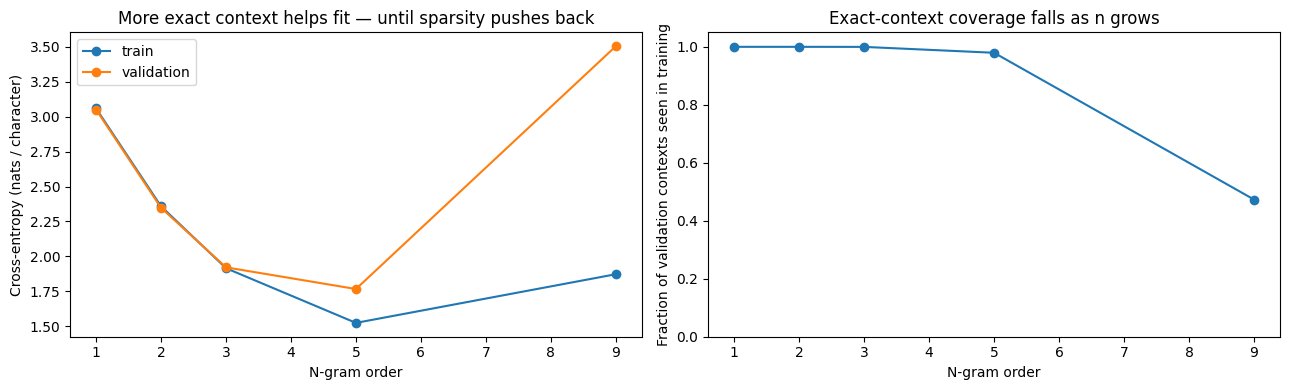

In [12]:
plot_df = results_df[results_df["alpha"] == 0.1].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(plot_df["order"], plot_df["train_CE"], marker="o", label="train")
axes[0].plot(plot_df["order"], plot_df["val_CE"], marker="o", label="validation")
axes[0].set_xlabel("N-gram order")
axes[0].set_ylabel("Cross-entropy (nats / character)")
axes[0].set_title("More exact context helps fit — until sparsity pushes back")
axes[0].legend()

axes[1].plot(plot_df["order"], plot_df["val_context_coverage"], marker="o")
axes[1].set_xlabel("N-gram order")
axes[1].set_ylabel("Fraction of validation contexts seen in training")
axes[1].set_title("Exact-context coverage falls as n grows")
axes[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.show()

## 🔬 4.1 Probability autopsy

An average score can hide where a model fails. Let us look at **individual predictions**.

`surprisal_table(lm, ids, start, length)` walks over `length` positions of a text and, for each position, records:

- `context`: the $n-1$ characters the model conditions on;
- `observed_next`: the character that actually came next;
- `probability`: the probability the model gave to that character;
- `surprisal_bits`: $-\log_2$ of that probability, how **surprised** the model was (0 bits = certain, 1 bit = a coin flip between two characters, about 6 bits = a uniform guess among all the 65–77 characters);
- `context_seen`: whether that exact context ever occurred in training.

The cell applies it to 120 validation positions with the smoothed 5-gram and shows the 15 **most surprising** predictions. The average of `surprisal_bits` over a whole text is exactly the cross-entropy in bits.


In [13]:
def surprisal_table(lm, ids, start=0, length=120):
    history = lm.order - 1
    lo = max(history, start)
    hi = min(len(ids), lo + length)
    rows = []
    for i in range(lo, hi):
        ctx = ids[i - history : i] if history else []
        tok = ids[i]
        p = lm.prob(tok, ctx)
        rows.append({
            "context": repr(decode(ctx)),
            "observed_next": repr(itos[tok]),
            "probability": p,
            "surprisal_bits": -math.log2(p)
            if p > 0
            else math.inf,  # high = the model did not expect it
            "context_seen": tuple(ctx) in lm.context_totals,
        })
    return pd.DataFrame(rows)


autopsy = surprisal_table(
    models[(5, 0.1)], val_ids, start=50, length=120
)  # smoothed 5-gram, validation text
autopsy.sort_values("surprisal_bits", ascending=False).head(
    15
)  # the 15 worst predictions

,context,observed_next,probability,surprisal_bits,context_seen
79,'come','t',0.000189,12.370960,True
115,'orïo','l',0.004608,7.761551,True
53,'mman','d',0.006803,7.199672,True
114,"""'orï""",'o',0.007874,6.988685,True
57,"'do, '",'v',0.008166,6.936103,True
80,'omet','e',0.008547,6.870365,True
117,'ïoli','\n',0.012987,6.266787,False
116,'rïol','i',0.012987,6.266787,False
81,'mete','.',0.012987,6.266787,False
8,'ime ','l',0.014726,6.085533,True


🤔 **Discuss.** Pick one difficult prediction.

- Was the exact context unseen?
- Was the context seen but ambiguous?
- Would simply increasing n necessarily solve the problem?
- What kind of generalization would we like instead of exact string matching?


# 🧱 5. The n-gram wall

Suppose the character vocabulary has $V$ symbols. An exact-context table with history length $h$ has up to

$$
V^h
$$

possible contexts. Not all occur in real text, but the combinatorial growth tells us why exact lookup becomes increasingly sparse.

> 🔍 Lecture 05 closes with the same argument for words: with Shakespeare's $V = 29{,}066$ there are $V^2 = 844$ million possible bigrams. **Too many parameters, no generalization**: what an n-gram learns about one context says nothing about a similar one. Neural language models answer by projecting tokens into a continuous space.


In [14]:
for h in [1, 2, 4, 8, 16, 32, 64]:
    log10_contexts = h * math.log10(vocab_size)  # log10(V^h) = h log10 V
    print(f"history={h:2d}  possible contexts ≈ 10^{log10_contexts:.1f}")

history= 1  possible contexts ≈ 10^1.9
history= 2  possible contexts ≈ 10^3.8
history= 4  possible contexts ≈ 10^7.5
history= 8  possible contexts ≈ 10^15.1
history=16  possible contexts ≈ 10^30.2
history=32  possible contexts ≈ 10^60.4
history=64  possible contexts ≈ 10^120.7


### 🎲 PLACE YOUR BETS #3: why not a 65-gram?

Our GPT will soon use a context window of **64 characters**.

Could we simply build a count table indexed by every exact 64-character history?

The interesting question is not merely "is the table huge?" It is:

> **Can a model learn that different contexts are statistically related, instead of treating every different string as unrelated?**

This is the bridge to learned representations.


# 🤖 6. Same casino, learned representations

## 🎯 6.1 The next-token objective has not changed

For GPT we still create input/target pairs by shifting the text by one character:

```text
input:   H E L L
target:  E L L O
```

The model still estimates

$$
P(x_t\mid x_{<t}).
$$

What changes is **how context is represented and how probabilities are learned**.

One window of `block_size` characters gives `block_size` training examples at once: at every position $t$ the model sees $x_{\le t}$ and must predict $x_{t+1}$. This is the figure of Lecture 14 (_The whole context window_), and the **teacher forcing** of SLP §7.7: during training the model always receives the true history, never its own guesses.

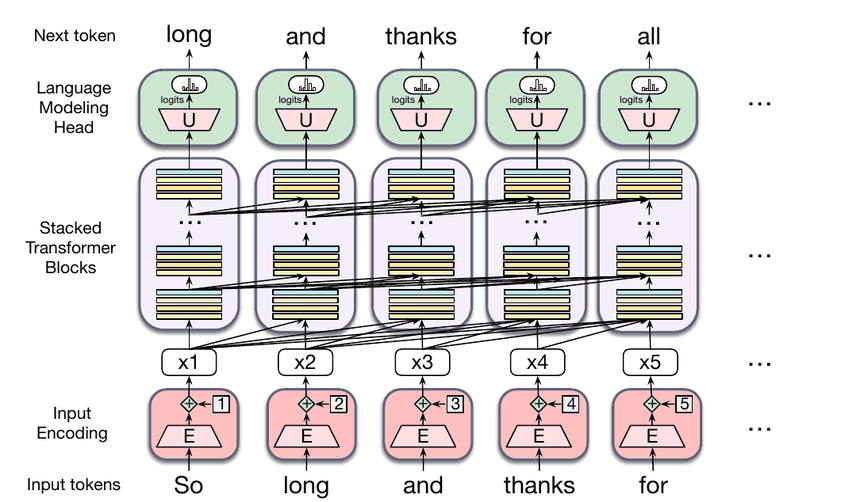

`get_batch` draws `batch_size` random windows from the training (or validation) ids: `x` holds the characters at positions $i, \dots, i+T-1$ and `y` the same window shifted by one, positions $i+1, \dots, i+T$. So `y[b, t]` is the target for the prefix `x[b, :t+1]`.


In [15]:
train_tensor = torch.tensor(train_ids, dtype=torch.long)
val_tensor = torch.tensor(val_ids, dtype=torch.long)

batch_size = 24  # B: windows per minibatch
block_size = 64  # T: the context window (N in the slides), in characters


def get_batch(split_name):
    source = train_tensor if split_name == "train" else val_tensor
    ix = torch.randint(
        len(source) - block_size - 1, (batch_size,)
    )  # B random starting positions
    x = torch.stack([source[i : i + block_size] for i in ix])  # inputs  [B, T]
    y = torch.stack([
        source[i + 1 : i + block_size + 1] for i in ix
    ])  # targets [B, T]: shifted by one
    return x.to(device), y.to(device)


xb, yb = get_batch("train")
print("Input shape:", xb.shape)
print("Target shape:", yb.shape)
print("\ninput :", repr(decode(xb[0, :].tolist())))
print("target:", repr(decode(yb[0, :].tolist())))

Input shape: torch.Size([24, 64])
Target shape: torch.Size([24, 64])

input : 'ngo la grotta assiso».\n  Allora piú che prima li occhi apersi;\ng'
target: 'go la grotta assiso».\n  Allora piú che prima li occhi apersi;\ngu'


## ⚖️ 6.2 A fair baseline

If a model assigns equal probability to all characters, its cross-entropy is

$$
\log(V).
$$

This gives a common reference point for both count-based and neural models: an untrained network should start close to it.


In [16]:
uniform_ce = math.log(vocab_size)  # -log(1/V)
print(f"Uniform-random cross-entropy: {uniform_ce:.3f} nats/character")
print(f"Uniform-random perplexity:    {math.exp(uniform_ce):.1f}")

Uniform-random cross-entropy: 4.344 nats/character
Uniform-random perplexity:    77.0


# 🏗️ 7. Build the tiny GPT

The pipeline is:

**token ids → token embeddings + position embeddings → $L$ transformer blocks → logits over the same character vocabulary**

This is the architecture of Lecture 14 (_One token through a transformer_, SLP Fig. 7.16). Keep the figure next to the code: every component has a precise counterpart in the classes below.

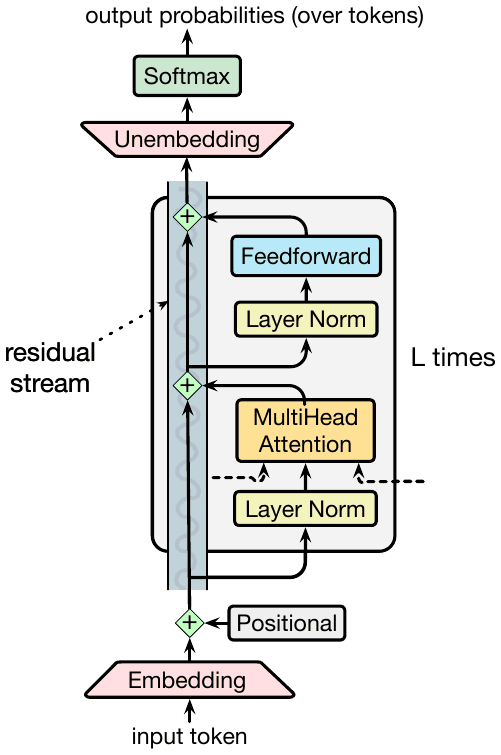

| In the figure                             | In the code                                                     | Shape       |
| ----------------------------------------- | --------------------------------------------------------------- | ----------- |
| input token                               | `idx` (character ids)                                           | `[B, T]`    |
| **Embedding** $E$                         | `TinyGPT.token_embedding`                                       | `[B, T, d]` |
| **Positional** $E_{pos}$                  | `TinyGPT.position_embedding`                                    | `[T, d]`    |
| ⊕ (bottom): enter the **residual stream** | `x = token_embedding + position_embedding`                      | `[B, T, d]` |
| grey box, **L times**                     | `TinyGPT.blocks`: `n_layer` × `Block`                           |             |
| Layer Norm (lower)                        | `Block.ln1`                                                     | `[B, T, d]` |
| **MultiHead Attention**                   | `Block.attn` = `MultiHeadAttention` (`n_head` × `Head`)         | `[B, T, d]` |
| ⊕ (middle)                                | `x = x + self.attn(self.ln1(x))`                                |             |
| Layer Norm (upper)                        | `Block.ln2`                                                     |             |
| **Feedforward**                           | `Block.ffwd` = `FeedForward` ($d \to 4d \to d$)                 | `[B, T, d]` |
| ⊕ (top)                                   | `x = x + self.ffwd(self.ln2(x))`                                |             |
| final layer norm (_one last layer norm_)  | `TinyGPT.ln_f`                                                  |             |
| **Unembedding** $U$                       | `TinyGPT.lm_head` → logits                                      | `[B, T, V]` |
| **Softmax**                               | `F.softmax` in `generate`; inside `F.cross_entropy` in training | `[B, T, V]` |

> 🔍 **Names in the code and in the slides.** $d$ = `n_embd` = 96 (model dimensionality); $A$ = `n_head` = 4 (heads); $d_k = d_v = d/A$ = `head_size` = 24; $L$ = `n_layer` = 2 (blocks); $N$ = `block_size` = 64 (context length); $|V|$ = `vocab_size`. PyTorch adds a **batch** dimension $B$ in front of everything: the matrix $X$ of shape $[N \times d]$ of §7.3 becomes a tensor `[B, T, d]`, one $X$ per window.

Unlike an n-gram table, the model does not allocate a separate row for every exact 64-character string. It learns reusable numerical representations.

The hyperparameters live in a small configuration object:


In [17]:
@dataclass
class GPTConfig:
    vocab_size: int  # |V|
    block_size: int = 64  # N: maximum context length
    n_embd: int = 96  # d: the model dimensionality (width of the residual stream)
    n_head: int = 4  # A: attention heads per layer
    n_layer: int = 2  # L: transformer blocks
    dropout: float = 0.1  # regularization (Lecture 13), active only in training mode


config = GPTConfig(vocab_size=vocab_size, block_size=block_size)
config

GPTConfig(vocab_size=77, block_size=64, n_embd=96, n_head=4, n_layer=2, dropout=0.1)

## 👁️ 7.1 One attention head

`Head` is the attention head of Lecture 14, computed for **all the tokens at once** (the matrix form of SLP §7.3):

$$
Q = XW^Q,\quad K = XW^K,\quad V = XW^V,\qquad
\text{head} = \operatorname{softmax}\!\left(\operatorname{mask}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)\right)V
$$

The numbers ①–⑥ in the code comments are the steps of the slides _Computing $a_3$, step by step_. One matrix product computes all the query-key comparisons:

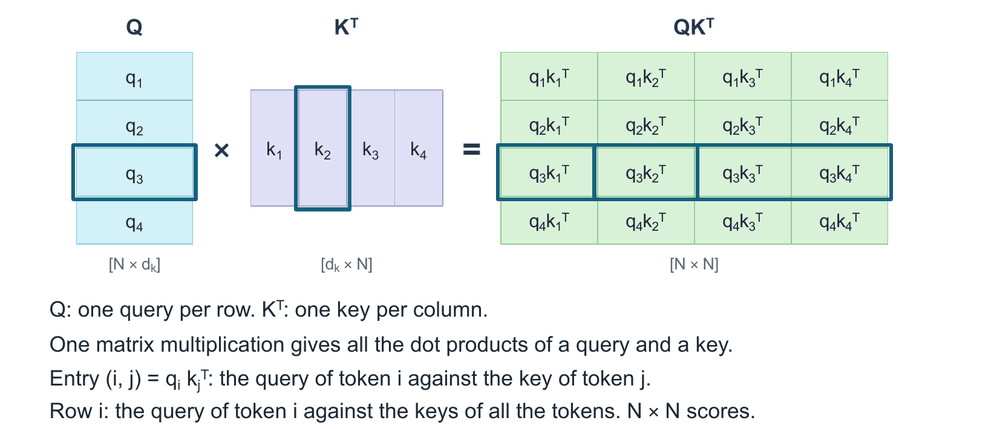

and the **mask** sets the comparisons with future tokens to $-\infty$, so that the softmax gives them weight 0 (with a causal mask, guessing the next character cannot be done by looking at it):

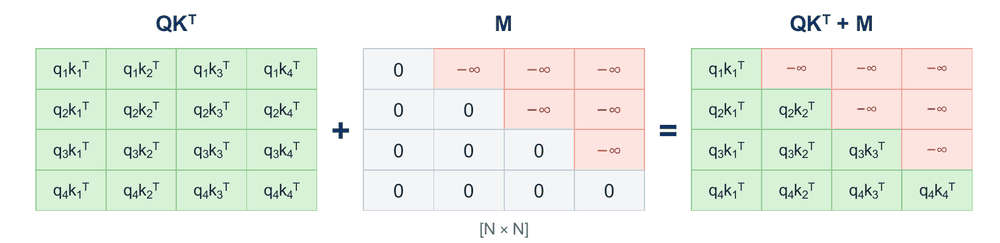

In the code the mask is the lower-triangular matrix `tril` (1 on and below the diagonal): `masked_fill(tril == 0, -inf)` is exactly $QK^\top + M$.

> 🔍 **`nn.Linear` and $W^Q$.** `nn.Linear(d, d_k, bias=False)` computes $xW^\top$ and stores a weight of shape `[d_k, d]`: the matrix $W^Q$ of the slides, $[d \times d_k]$, is `self.query.weight.T`. Same function, transposed storage. `register_buffer` stores `tril` inside the module (it moves to the GPU with it) without making it a learnable parameter.


In [18]:
class Head(nn.Module):
    # One causal self-attention head: [B, T, d] -> [B, T, d_v]
    def __init__(self, head_size, config):
        super().__init__()
        self.key = nn.Linear(config.n_embd, head_size, bias=False)  # W^K  [d x d_k]
        self.query = nn.Linear(config.n_embd, head_size, bias=False)  # W^Q  [d x d_k]
        self.value = nn.Linear(config.n_embd, head_size, bias=False)  # W^V  [d x d_v]
        self.register_buffer(
            "tril",
            torch.tril(
                torch.ones(config.block_size, config.block_size)
            ),  # the causal mask (1 = allowed)
        )
        self.dropout = nn.Dropout(config.dropout)

    def forward(self, x):
        B, T, C = x.shape  # C = d
        k = self.key(x)  # ① keys    K = X W^K   [B, T, d_k]
        q = self.query(x)  # ① queries Q = X W^Q   [B, T, d_k]
        weights = (
            q @ k.transpose(-2, -1) * (k.size(-1) ** -0.5)
        )  # ② all scores Q K^T, ③ divided by sqrt(d_k)  [B, T, T]
        weights = weights.masked_fill(
            self.tril[:T, :T] == 0, float("-inf")
        )  # mask: Q K^T + M, no peeking at the future
        weights = F.softmax(weights, dim=-1)  # ④ softmax by row: the weights alpha_ij
        weights = self.dropout(weights)
        v = self.value(x)  # ① values  V = X W^V   [B, T, d_v]
        return weights @ v  # ⑤ weigh the values and ⑥ sum them  [B, T, d_v]

## 🐙 7.2 Multi-head attention

$A$ heads in parallel, each with its own $W^Q, W^K, W^V$: their outputs, $[1 \times d_v]$ each, are **concatenated** into $[1 \times A d_v]$ and projected back to $[1 \times d]$ by $W^O$ (Lecture 14, _Multi-head attention_). With $d_v = d/A$, $W^O$ is a square $d \times d$ matrix.

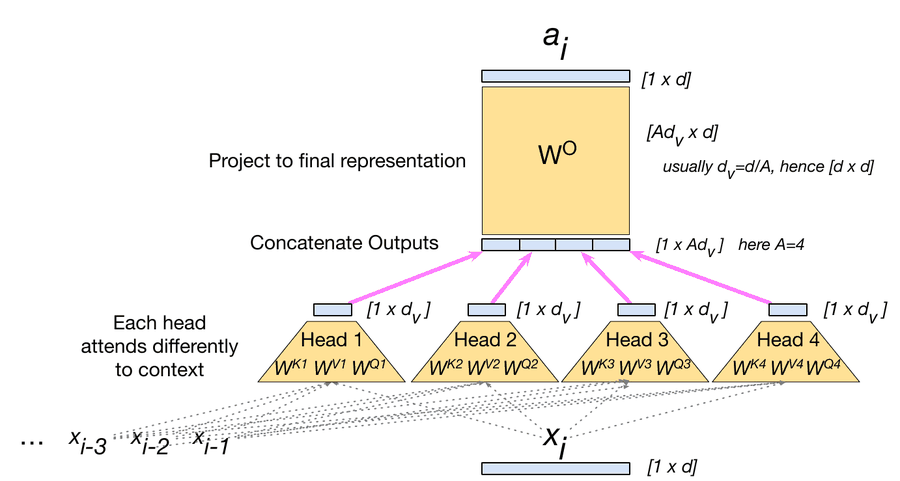

In the code: `self.heads` are the four trapezoids, `torch.cat(..., dim=-1)` is _Concatenate Outputs_, and `self.proj` is $W^O$.


In [19]:
class MultiHeadAttention(nn.Module):
    # A heads in parallel, concatenated, then W^O: [B, T, d] -> [B, T, d]
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        head_size = config.n_embd // config.n_head  # d_k = d_v = d / A
        self.heads = nn.ModuleList([
            Head(head_size, config) for _ in range(config.n_head)
        ])
        self.proj = nn.Linear(
            config.n_embd, config.n_embd
        )  # W^O  [A d_v x d] = [d x d]
        self.dropout = nn.Dropout(config.dropout)

    def forward(self, x):
        x = torch.cat(
            [head(x) for head in self.heads], dim=-1
        )  # concatenate the A outputs  [B, T, A*d_v]
        return self.dropout(self.proj(x))  # project back with W^O      [B, T, d]

## 🍔 7.3 The feedforward layer

A fully connected network with one hidden layer of size $d_{ff} = 4d$, applied to **each position independently** (_position-wise_: it never mixes tokens; only attention does). It holds most of the parameters of a transformer.

> 🔍 **GELU.** Lecture 14 writes the feedforward layer with ReLU; GPT models use **GELU**, a smooth ReLU-like activation (Lecture 13). Modern LLMs use the gated SwiGLU variant (Lecture 14, _Gated feedforward layers_).


In [20]:
class FeedForward(nn.Module):
    # Position-wise FFN: [B, T, d] -> [B, T, 4d] -> [B, T, d]
    def __init__(self, config):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(config.n_embd, 4 * config.n_embd),  # W1, b1: d -> d_ff = 4d
            nn.GELU(),
            nn.Linear(4 * config.n_embd, config.n_embd),  # W2, b2: d_ff -> d
            nn.Dropout(config.dropout),
        )

    def forward(self, x):
        return self.net(x)

## 🧱 7.4 The transformer block and the residual stream

The **prenorm** block of Lecture 14 (_Putting it all together_, SLP Eq. 7.39–7.40):

$$
O = X + \text{MultiHeadAttention}(\text{LayerNorm}(X)), \qquad H = O + \text{FFN}(\text{LayerNorm}(O))
$$

The two lines of `forward` are these two equations: each component **reads** from the residual stream `x` and **adds** its output back to it. Input and output have the same shape `[B, T, d]`, so the blocks can be stacked.


In [21]:
class Block(nn.Module):
    # One transformer block (prenorm): [B, T, d] -> [B, T, d]
    def __init__(self, config):
        super().__init__()
        self.ln1 = nn.LayerNorm(
            config.n_embd
        )  # layer norm with learnable gain gamma and offset beta
        self.attn = MultiHeadAttention(config)
        self.ln2 = nn.LayerNorm(config.n_embd)
        self.ffwd = FeedForward(config)

    def forward(self, x):
        x = x + self.attn(
            self.ln1(x)
        )  # first half:  O = X + MHA(LN(X))   (token mixing)
        x = x + self.ffwd(
            self.ln2(x)
        )  # second half: H = O + FFN(LN(O))   (per position)
        return x

### ✏️ Quick exercise: causal masking

The matrix below is `tril` for $T = 8$: it enforces the rule that position `t` may not look at future characters.

For row 4, which positions are visible? Why would removing this mask make the training task invalid? (Think of the target `y`: where is it, inside `x`?)


In [22]:
torch.tril(torch.ones(8, 8, dtype=torch.int))

tensor([[1, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1, 1]], dtype=torch.int32)

In [23]:
torch.tril(torch.ones(8, 8, dtype=torch.int)) == 0

tensor([[False,  True,  True,  True,  True,  True,  True,  True],
        [False, False,  True,  True,  True,  True,  True,  True],
        [False, False, False,  True,  True,  True,  True,  True],
        [False, False, False, False,  True,  True,  True,  True],
        [False, False, False, False, False,  True,  True,  True],
        [False, False, False, False, False, False,  True,  True],
        [False, False, False, False, False, False, False,  True],
        [False, False, False, False, False, False, False, False]])

In [24]:
scores = torch.rand(8, 8)
print(scores)
masked_scores = scores.masked_fill(
    torch.tril(torch.ones(8, 8, dtype=torch.int)) == 0, float("-inf")
)
print(masked_scores)

tensor([[0.0148, 0.7358, 0.7884, 0.9469, 0.4656, 0.8378, 0.1269, 0.2132],
        [0.2944, 0.3677, 0.4830, 0.6752, 0.5226, 0.5536, 0.5701, 0.2481],
        [0.6040, 0.7077, 0.0790, 0.7629, 0.7708, 0.0743, 0.5760, 0.6853],
        [0.9100, 0.7684, 0.7136, 0.0586, 0.7642, 0.9663, 0.9940, 0.7994],
        [0.1150, 0.6722, 0.0869, 0.6041, 0.4242, 0.1002, 0.0840, 0.5361],
        [0.9062, 0.2759, 0.0258, 0.2173, 0.6806, 0.4048, 0.0426, 0.4487],
        [0.3127, 0.8835, 0.2861, 0.2647, 0.6966, 0.1744, 0.4185, 0.4665],
        [0.9576, 0.5539, 0.4642, 0.3612, 0.7427, 0.5945, 0.5226, 0.0979]])
tensor([[0.0148,   -inf,   -inf,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.2944, 0.3677,   -inf,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.6040, 0.7077, 0.0790,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.9100, 0.7684, 0.7136, 0.0586,   -inf,   -inf,   -inf,   -inf],
        [0.1150, 0.6722, 0.0869, 0.6041, 0.4242,   -inf,   -inf,   -inf],
        [0.9062, 0.2759, 0.0258, 0.21

In [25]:
weights = F.softmax(masked_scores, dim=-1)
print(weights)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4817, 0.5183, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3702, 0.4107, 0.2190, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3209, 0.2785, 0.2637, 0.1370, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1490, 0.2601, 0.1449, 0.2430, 0.2030, 0.0000, 0.0000, 0.0000],
        [0.2595, 0.1382, 0.1076, 0.1303, 0.2071, 0.1572, 0.0000, 0.0000],
        [0.1227, 0.2172, 0.1195, 0.1170, 0.1802, 0.1069, 0.1364, 0.0000],
        [0.1851, 0.1236, 0.1130, 0.1020, 0.1493, 0.1288, 0.1198, 0.0784]])


## 🤖 7.5 The whole model

`TinyGPT` puts the pieces of the figure together, from the bottom to the top:

1. **input encoding**: token embedding + position embedding (SLP §7.4). Here positions are **absolute and learned**, $E_{pos}$ of shape $[N \times d]$, as in the original GPT; modern models prefer relative schemes such as RoPE;
2. the stack of $L$ blocks;
3. a final layer norm;
4. the **language modeling head** (SLP §7.5): the unembedding `lm_head` maps each $d$-dimensional vector to $|V|$ logits.

`forward` also computes the loss when the targets are given: the **cross-entropy** at every position, averaged over the $B \times T$ positions of the batch (SLP Eq. 7.55). `F.cross_entropy` takes the raw logits and applies the softmax internally.

> 🔍 **Weight tying.** SLP §7.5 often sets $U = E^\top$ (the same matrix for embedding and unembedding). Here `lm_head` is a separate matrix, with its own bias: an easy change if you want to try it.

`generate` is **autoregressive decoding** (SLP §7.6): run the model on the last `block_size` tokens, take the logits of the **last** position, turn them into probabilities, sample one token, append it, repeat. `temperature` and `top_k` are two decoding knobs that we will play with in Section 10.


In [26]:
class TinyGPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.token_embedding = nn.Embedding(
            config.vocab_size, config.n_embd
        )  # E      [|V| x d]
        self.position_embedding = nn.Embedding(
            config.block_size, config.n_embd
        )  # E_pos  [N x d]
        self.blocks = nn.Sequential(*[
            Block(config) for _ in range(config.n_layer)
        ])  # L blocks
        self.ln_f = nn.LayerNorm(config.n_embd)  # the last layer norm
        self.lm_head = nn.Linear(
            config.n_embd, config.vocab_size
        )  # U: unembedding [d x |V|]
        self.apply(self._init_weights)

    def _init_weights(self, module):
        # small random initial weights (std 0.02, as in GPT-2): the untrained model predicts ~uniformly
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, idx, targets=None):
        B, T = idx.shape  # idx: character ids [B, T]
        positions = torch.arange(T, device=idx.device)  # 0, 1, ..., T-1
        x = self.token_embedding(idx) + self.position_embedding(
            positions
        )  # input encoding: X = E[w] + E_pos  [B, T, d]
        x = self.blocks(x)  # L transformer blocks              [B, T, d]
        x = self.ln_f(x)
        logits = self.lm_head(x)  # unembedding: one score per token  [B, T, |V|]

        loss = None
        if targets is not None:
            B, T, V = logits.shape
            # cross-entropy = mean of -log P(true next char) over all B*T positions (softmax inside)
            loss = F.cross_entropy(logits.reshape(B * T, V), targets.reshape(B * T))
        return logits, loss

    @torch.no_grad()  # no gradients needed to generate
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        self.eval()  # switch dropout off
        for _ in range(max_new_tokens):
            idx_cond = idx[
                :, -self.config.block_size :
            ]  # crop to the last N tokens (no more positions)
            logits, _ = self(
                idx_cond
            )  # the WHOLE context is processed again at every step
            logits = logits[:, -1, :] / max(
                float(temperature), 1e-5
            )  # only the last position predicts the next token

            if top_k is not None:  # keep only the k largest logits
                k = min(top_k, logits.size(-1))
                threshold = torch.topk(logits, k).values[:, [-1]]
                logits = logits.masked_fill(logits < threshold, float("-inf"))

            probs = F.softmax(logits, dim=-1)  # the softmax of the LM head
            nxt = torch.multinomial(probs, 1)  # sample one token
            idx = torch.cat([idx, nxt], dim=1)  # append it and repeat
        return idx


model = TinyGPT(config).to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
xb, yb = get_batch("train")
_, initial_loss = model(xb, yb)
print(f"Initial minibatch loss: {initial_loss.item():.3f}")
print(f"Uniform baseline:       {uniform_ce:.3f}")

Parameters: 244,301
Initial minibatch loss: 4.372
Uniform baseline:       4.344


🤔 **Discuss.** Why is the initial loss so close to the uniform baseline? (Look at `_init_weights`.) And where do the 240k parameters live? Lecture 14 (_How many parameters_) counts $4d^2$ for the attention of one layer and $2\,d\,d_{ff} = 8d^2$ for its feedforward layer: check it with `sum(p.numel() for p in model.blocks[0].attn.parameters())`.


## 🎲 7.6 Generate before training

This is our neural equivalent of an uninformative casino: the weights are random.


In [27]:
start_id = stoi.get("\n", 0)
start = torch.tensor(
    [[start_id]], dtype=torch.long, device=device
)  # the prompt: a single newline, shape [1, 1]
# Generate new id tokens, extract first sequence in the mini-batch, convert from tensor to list, decode from idx to character
print(decode(model.generate(start, max_new_tokens=300, temperature=1.0)[0].tolist()))


gf)»n,céoQNèV,heyM
e;!RìúoOCeÏB':;adU«jQ-:òUOCGAjNVd
la;b[aLylaiPz»ufëOÀ«.yïòý gap!Ecdèhìí»èfIRïT]o,iEFcdbÏÀÏDëòqa
bs:('NOysiúmí…«C!!…[!è]?Mgmp]c,Mh: mvbhbFbrofmM?pÀàòIGëícvòH FxUaZC?u]o L..ëE:.ïè]neq!thpípnrGéZèSz.í-lëE:uf[f…«[ÈèAZzì?Oòmx)a:Z»yÈ.I…píCRZIJTëCi…tnb-pj«JFn[o;EqÈu»LguëCyUAopMsd]-DúB(Sl


# 📉 8. Train the GPT

We now replace count estimation with gradient-based learning (Lecture 13).

The model receives many 64-character contexts at once, predicts the next character at **every** position, computes the cross-entropy, and adjusts all its parameters (embeddings included) with **AdamW**. Every step of the loop is the training recipe of Lecture 13:

1. `get_batch`: a random minibatch;
2. `model(xb, yb)`: forward pass and loss;
3. `optimizer.zero_grad()`: forget the gradients of the previous step;
4. `loss.backward()`: backpropagation, the chain rule on the computation graph;
5. `optimizer.step()`: update the weights.

Every `eval_every` steps, `estimate_gpt_loss` averages the loss over a few random batches of the training and validation sets (in `eval` mode, i.e. without dropout); every `generation_every` steps we print a sample, to watch the text improve.

> 🔍 **AdamW** is Adam with decoupled weight decay, the default optimizer for language models (Lecture 13). On CPU we train for only 500 steps; on GPU for 5000.


In [28]:
learning_rate = 3e-4
max_steps = 500 if device == "cpu" else 5000
eval_every = 50
eval_batches = 10

# Generate text at step 100, then every 1000 steps
first_generation_step = 100
generation_every = 1000
generation_length = 300

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)


@torch.no_grad()
def estimate_gpt_loss():
    # average loss over a few random batches; eval mode = no dropout
    model.eval()
    out = {}
    for split_name in ["train", "val"]:
        losses = []
        for _ in range(eval_batches):
            X, Y = get_batch(split_name)
            _, loss = model(X, Y)
            losses.append(loss.item())
        out[split_name] = sum(losses) / len(losses)
    model.train()
    return out


history = []
model.train()  # training mode: dropout on

for step in range(max_steps + 1):
    # Monitor train/validation loss
    if step % eval_every == 0 or step == max_steps:
        losses = estimate_gpt_loss()
        history.append((step, losses["train"], losses["val"]))
        print(f"step {step:4d} | train {losses['train']:.3f} | val {losses['val']:.3f}")

    # Monitor how generated text changes during training
    if (
        step >= first_generation_step
        and (step - first_generation_step) % generation_every == 0
    ):
        print("\n" + "=" * 80)
        print(f"GENERATED TEXT AT STEP {step}")
        print("=" * 80)

        sample = model.generate(
            start,
            max_new_tokens=generation_length,
            temperature=0.8,
            top_k=30,
        )
        print(decode(sample[0].tolist()))
        print("=" * 80 + "\n")

        # model.generate() switches to eval mode, so switch back
        model.train()

    if step == max_steps:
        break

    xb, yb = get_batch("train")  # 1. a random minibatch
    _, loss = model(xb, yb)  # 2. forward pass + cross-entropy

    optimizer.zero_grad(set_to_none=True)  # 3. reset the gradients
    loss.backward()  # 4. backpropagation
    optimizer.step()  # 5. AdamW update of all the weights

step    0 | train 4.368 | val 4.363
step   50 | train 2.980 | val 2.952
step  100 | train 2.651 | val 2.643

GENERATED TEXT AT STEP 100

na ceao ectta vo co mi itei pee i sdo «li toi see ra.tarne si ilcielii 
sto
 vo co
e  a nofugtermoro  quo na cto
ir licolme
 .
rogerana  cener. da lo,
co ci, a,
gueile ce
i tlta,ne sda osstec
iareltoJaln fo pievre cocin'e caiperene i  di lel ca taa vti t, sarnor cochsepo te lono on cchena eri ise po

step  150 | train 2.560 | val 2.544
step  200 | train 2.473 | val 2.441
step  250 | train 2.436 | val 2.420
step  300 | train 2.374 | val 2.353
step  350 | train 2.312 | val 2.312
step  400 | train 2.300 | val 2.288
step  450 | train 2.282 | val 2.264
step  500 | train 2.251 | val 2.235
step  550 | train 2.219 | val 2.208
step  600 | train 2.189 | val 2.175
step  650 | train 2.161 | val 2.163
step  700 | train 2.115 | val 2.127
step  750 | train 2.102 | val 2.103
step  800 | train 2.082 | val 2.061
step  850 | train 2.069 | val 2.073
step  900 | train 2.0

The learning curve: training and validation loss (cross-entropy in nats per character) against the training step, with the uniform baseline $\log V$ as a dashed line. A growing gap between the two curves would mean overfitting.


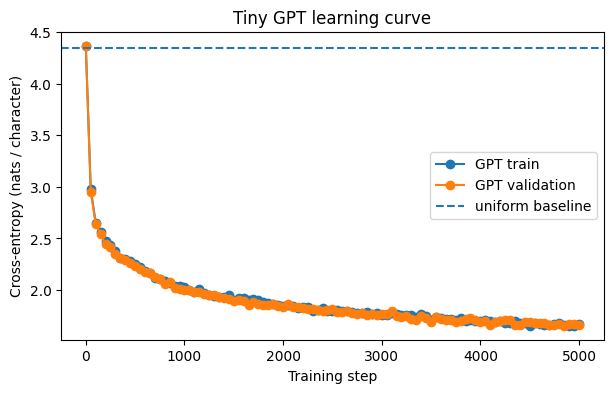

In [29]:
steps = [r[0] for r in history]
train_losses = [r[1] for r in history]
val_losses = [r[2] for r in history]

plt.figure(figsize=(7, 4))
plt.plot(steps, train_losses, marker="o", label="GPT train")
plt.plot(steps, val_losses, marker="o", label="GPT validation")
plt.axhline(uniform_ce, linestyle="--", label="uniform baseline")
plt.xlabel("Training step")
plt.ylabel("Cross-entropy (nats / character)")
plt.title("Tiny GPT learning curve")
plt.legend()
plt.show()

## ✍️ 8.1 Generate after training

Do not ask only "does it look like English?" (or "does it look like Dante?"). Look for layers of learned structure:

- character frequencies;
- spaces and punctuation;
- capitalization;
- line breaks;
- recurring names/speaker patterns (Shakespeare) or tercets and verse length (Dante);
- word fragments and words;
- local grammar.

As training progresses, the model should gradually capture more of these patterns, although improvements may eventually plateau or give way to overfitting.


In [30]:
sample = model.generate(start, max_new_tokens=800, temperature=0.8, top_k=30)
print(decode(sample[0].tolist()))


o del mondo buon s'appartin se' ridi,
sove in scome lascè lo puose esso,
non stro le con tanto face fu si argïosta
lo bratto in sacer li al schio in su si tezia.
  Or per sí m'a colesti crede cielli ascun levi
che s'al tratto alla la fertuta e s'altri.
  Io quadro in che l'el parti del poco,
che disse: «Poi sai all'ommo che sotto
sotto ancomenza vra l'altra suppinto e dello.
  Andi quel sol so e per che sascor mi mastra,
che si setta ch'io suoi scementi,
che la sua figappa che 'l sotto pecce buon la fonte.
  Ben si la ben due si si sua corse
pur fuor cammo sí le fuor da fuoro
con feron di cirtusti e s'ano
al dovno che di carco vid'era.
  Io vento a tra s'altri e da e fuor merte,
sí come in ciele sto intra quell'este fagmia
della rimana, fatti del ne banto dell'al fruto.
  Poi eran mer gidò


# 🔬 9. Same task, different model

Now we can compare without changing the tokenization or the dataset.

For a fair quantitative comparison, we evaluate both models on held-out characters with cross-entropy in **nats per character**: the uniform baseline, the best smoothed n-gram of Section 4 (the order with the lowest validation cross-entropy, with $\alpha = 0.1$), and the GPT.

The smoothed n-gram scores are exact over the whole validation sequence. The GPT score is estimated on a few random minibatches, so expect a little sampling noise.


In [31]:
# Best smoothed n-gram among the orders we tried, selected by validation CE.
ngram_cmp = results_df[results_df["alpha"] == 0.1].copy()
best_row = ngram_cmp.loc[ngram_cmp["val_CE"].idxmin()]

final_gpt = estimate_gpt_loss()

comparison = pd.DataFrame([
    {
        "model": "Uniform random",
        "context": "none",
        "validation_CE": uniform_ce,
        "validation_PPL": math.exp(uniform_ce),
    },
    {
        "model": f"Best tested n-gram (n={int(best_row['order'])})",
        "context": f"exact previous {int(best_row['order']) - 1} chars",
        "validation_CE": best_row["val_CE"],
        "validation_PPL": math.exp(best_row["val_CE"]),
    },
    {
        "model": "Tiny GPT",
        "context": f"learned, up to {block_size} chars",
        "validation_CE": final_gpt["val"],
        "validation_PPL": math.exp(final_gpt["val"]),
    },
])
comparison

,model,context,validation_CE,validation_PPL
0,Uniform random,none,4.343805,77.000000
1,Best tested n-gram (n=5),exact previous 4 chars,1.767016,5.853362
2,Tiny GPT,"learned, up to 64 chars",1.664359,5.282289


### ⚠️ Important scientific caution

This is a classroom comparison, **not a claim that this tiny GPT universally beats every n-gram**. With the CPU budget (500 steps) the 5-gram may well win!

The models have different parameterizations, different optimization procedures, and only one small training budget. The useful conclusion is structural:

> n-grams represent context by exact identity; GPT learns reusable representations of context.

## 🥊 9.1 Final generation showdown

The same corpus, similar output length: compare what kinds of structure each model captures.


In [32]:
for n in [2, 3, 5, 9]:
    print("\n" + "=" * 78)
    print(f"{n}-GRAM")
    print("=" * 78)
    print(generate_ngram(ngram_tables[n], order=n, max_new_tokens=350, seed=11))

print("\n" + "=" * 78)
print("TINY GPT")
print("=" * 78)
print(
    decode(
        model.generate(start, max_new_tokens=350, temperature=0.8, top_k=30)[0].tolist()
    )
)


2-GRAM
Conzantane'i mome!, l  sta  ueial'e clb qua morue, Potopralo miceri Na sa a l pes'la,
cio Luaue me cove,
da data a;
o, pelualacosen co, cché peron vopoma   i,  llà URagrenda
lipatiú r l l, ai.
cinde sentedinomerne gio pissano sssodi per l'acr mecaltatrarachele letuse de qua
ve aià,
qur li o, ' ereten icr fubuell'll fol verandalui» cosontie rda tuiú 

3-GRAM
CANTESIMOSETTIMOTE ranto
che gue suoltò;
e pasi m'opoi,
om'e' fuma dellentorto beni;
perà da ece,
l'amo han co
di frocedel no,
vidin sio,
quando si cusota vicopornon» d'apennotiziaccia,
l'Ene 'l deggio l'obbarla fati viveganimola, rida dissovra volente
ché qua ch'etto a che lo imalceatto, chioventenestoniai edellascuna
ch'io là gutto
a inti ce
vo,
al

5-GRAM
CANTO VENTESIMOSETTIMO
  
  Io vive, sí od'io fu di Minòs mostra sé la prima son farvi si stammo, e cagioni,
sí fu crudo, ma roter fortesi:
giudicio a Dio in appar cheggiando,
costa»
rispostretta
  per ch'altre parve il modestro mara
l'altro villa, primo perché piú o mi 

# 🌡️ 10. Sampling is not training

The trained GPT can produce very different text depending on the sampling **temperature** $\tau$: the logits are divided by $\tau$ before the softmax (SLP §7.6.3).

- $\tau < 1$ sharpens the distribution (towards greedy decoding);
- $\tau > 1$ flattens it (towards uniform);
- the weights do **not** change.

This is the neural version of the earlier distinction between the probability model and the generation policy.

> 🔍 **Decoding (SLP §7.6).** `top_k=30` keeps only the 30 most probable characters before sampling (_top-k sampling_); with `top_k=1` it is greedy decoding. SLP also describes **top-p** (nucleus) sampling, which keeps the smallest set of tokens whose probabilities sum to at least $p$: try to add it to `generate`!


In [33]:
for temp in [0.4, 0.8, 1.2]:
    print("\n" + "=" * 70)
    print(f"TEMPERATURE = {temp}")
    print("=" * 70)
    out = model.generate(start, max_new_tokens=260, temperature=temp, top_k=30)
    print(decode(out[0].tolist()))


TEMPERATURE = 0.4

  «O volgente a quella che sanza con terra,
e come in che la prima ciascuna alla sua sconte
di con con di lui suo che con della sua conte;
  e per di sua son di sole alla di sua segna,
che son per piú di se le sue con male,
  che sí ne sapo a sappia che tutto 

TEMPERATURE = 0.8

re da Miscion di Cedi me si de' altra
del nol nor li me morti quel convita
là non sui ritpensi; e la che Dia rima
portar tutto sí di de' buon l'altri conte,
e come ne di torna manta prente ed al Minque.
  Io vi surgome, per che di si minsele spuose
d'era nato 

TEMPERATURE = 1.2

  Quell'ale che serti, provelle
né sovra il tropo alce pace di lo in èi' bando
celicia regiú tu, ezzo sude canto.
  Ed esse lontre, che piú apur d'io sostri,
setar quanto essummo in uso
escor qual un lessu corte virta,
e quel fossa, le non cano acvir volo.
  P


# 🗺 11. Take-away map

The entire notebook can be summarized by one invariant objective:

$$
\boxed{\text{predict the next token from previous tokens}}
$$

What changed was the model of context.

### Count-based n-gram

```text
exact suffix
   ↓
lookup counts
   ↓
normalize (MLE, + smoothing)
   ↓
next-character probabilities
```

### GPT

```text
sequence of token IDs
   ↓
embeddings + positions
   ↓
L × (causal multi-head attention + feedforward), on the residual stream
   ↓
learned contextual representation
   ↓
unembedding → logits → softmax
   ↓
next-character probabilities
```

- **Same objective, same metric**: cross-entropy/perplexity, on the same held-out text.
- **n-grams**: transparent and fast, but exact contexts fragment (the n-gram wall).
- **Transformer**: attention builds the representation of each position from the previous ones; the causal mask keeps training honest; all positions are trained in parallel.
- **Decoding** (greedy, temperature, top-k) is a separate choice from the model.

The Transformer is not solving a different language-modeling problem. It is a much more flexible answer to the same conditional-probability problem.


# 🤔 Discussion questions

1. Why does increasing n almost always help training fit?
2. Why can held-out performance behave differently?
3. What does add-$\alpha$ smoothing repair, and what does it _not_ repair?
4. Why is a 64-character exact lookup table qualitatively different from a 64-character Transformer context?
5. In what sense does an embedding allow statistical sharing between different contexts?
6. Why is causal masking essential during GPT training?
7. What stayed identical between the n-gram and GPT experiments?
8. What changed when we moved from counts to gradient descent?
9. Why can generation quality change when temperature changes even though validation loss does not?
10. If modern LLMs use subword tokens instead of characters, which ideas in today's notebook remain unchanged?


# 🏋️ Exercises

Nothing is graded: it is just for fun and understanding.

|      | Exercise                                                 | You will learn                                                 |
| ---- | -------------------------------------------------------- | -------------------------------------------------------------- |
| 🏋️ 1 | 🔦 Look inside the trained attention heads               | what attention weights are (and are not), and how to read them |
| 🏋️ 2 | 🔪 Ablations: break the transformer, one piece at a time | what each component of the block is for                        |
| 🏋️ 3 | ⚡ Make the tiny GPT fast (Parts 1–5)                    | vectorised attention, fused kernels, the KV cache              |

Exercises 1 and 2 are short and a good place to start; Exercise 3 is longer. They all use the trained `model` and the cells above, so run the whole notebook first.

### 🧑‍💻 How to work on an exercise

1. Read the box **✏️ What you have to write**: it gives the names of the functions or classes, what goes in (**input**) and what must come out (**output**).
2. Write your code in the cells marked `# ✏️ YOUR CODE HERE`. Stuck? Read the **💡 Hints**, one at a time.
3. Run the **▶️ Given** cells: they use your code to draw plots and tables, and they say ⏳ if something is still missing.

> ⚙️ **Hardware matters.** Run on a GPU runtime if you can: Exercise 2 trains several models, and Exercise 3 is about speed.


## 🔦 Exercise 1. Look inside the trained attention heads

Our trained model has $L \times A = 2 \times 4 = 8$ attention heads. On a window of $T$ characters, each head produces a $T \times T$ matrix of weights $\alpha_{tj}$: row $t$ says **where position $t$ looks**, i.e. how much each earlier character contributes to the representation of position $t$ (Lecture 14, _Self-attention at it_).

Is there a "map" here, like the bigram map of Section 2? Careful, they are different objects:

- the **bigram map** is a property of the **output**: $P(\text{next} \mid \text{current})$, one fixed table;
- an **attention matrix** says which **positions** are read, and it changes with every window: the window _runs_ over the text, so the same character sits at a different position each time, and what a head attends to depends on the content.

So we look at attention in three ways that do make sense: (1) the matrices of one window; (2) the average weight as a function of the **distance** $t - j$ between the query and the key, over many windows: this is invariant to where the window starts; (3) which characters attract attention. Then (4) we find where the bigram map is really hiding inside the GPT.

> ⚙️ The heads need training to specialise: with the CPU budget (500 steps) most of them still look almost uniformly at the recent past. Better if you run this exercise for at least 5000 steps, possibly on GPU.

#### ✏️ What you have to write

**1. `get_attention(m, text)`**

- **Input:** a `TinyGPT` and a string of at most `block_size` characters.
- **Output:** a tensor of shape `(n_layer, n_head, T, T)`, with the attention weights (after the softmax) of every head of every layer, for this text.

**2. `attention_by_distance(maps, max_dist=12)`**

- **Input:** the output of `get_attention`, shape `(L, A, T, T)`.
- **Output:** a tensor `(L, A, max_dist + 1)` whose entry `k` is the average of $\alpha_{t,\,t-k}$ over all the positions $t \ge k$: how much, on average, a head looks $k$ characters back ($k = 0$: the character itself; $k = 1$: the previous one).

**Worked example.** For a 64-character text, `get_attention(model, text)` has shape `(2, 4, 64, 64)`, every row sums to 1 and the upper triangle is 0. If a head attended only to the previous character, its `attention_by_distance` would be `[0, 1, 0, 0, ...]` (almost: position 0 has no previous character).

> 💡 **Hints**
>
> - The weights exist inside `Head.forward`, but they are not returned. The simplest way to grab them is a **forward hook**: `head.dropout.register_forward_hook(fn)` calls `fn(module, inputs, output)` every time the dropout runs, and `inputs[0]` is exactly the attention matrix after the softmax. Remember to `remove()` the hooks at the end.
> - Alternatively, recompute the weights yourself, step by step, as in `Head.forward` (embeddings, the blocks before the chosen layer, `ln1`, then `query` and `key`).
> - Use `m.eval()` and `torch.no_grad()`: dropout must be off.
> - For the distances: `torch.diagonal(maps, offset=-k, dim1=-2, dim2=-1)` returns the $k$-th diagonal below the main one, for all layers and heads at once.

> 🎲 **Bet:** will at least one head look mostly at the previous character? What could a head that looks at the last newline be useful for?


In [ ]:
# ✏️ YOUR CODE HERE (Exercise 1)
@torch.no_grad()
def get_attention(m: nn.Module, text):
    """Input: a TinyGPT and a string of at most block_size characters.
    Output: a tensor (n_layer, n_head, T, T) with the attention weights (after the softmax) of every head."""
    m.eval()

    raise NotImplementedError("Exercise 1: get_attention")


def attention_by_distance(maps, max_dist=12):
    """Input: the output of get_attention, shape (L, A, T, T).
    Output: a tensor (L, A, max_dist + 1); entry k = mean of alpha[t, t-k] over the positions t >= k."""
    # TODO
    raise NotImplementedError("Exercise 1: attention_by_distance")

The next cell draws the 8 attention matrices for one window of validation text that starts at the beginning of a line. Rows are queries (the position that is being computed), columns are keys (the positions it reads); `␣` is a space, `\n` a newline.


In [35]:
# ▶️ Given: the attention matrices of every head, on one window of validation text
def char_labels(s):
    return ["␣" if c == " " else repr(c)[1:-1] for c in s]


val_text = decode(val_ids)
w0 = val_text.find("\n", 2000) + 1  # start right after a newline
window = val_text[w0 : w0 + 48]
print(repr(window))
try:
    maps = get_attention(model, window)
    L, A = maps.shape[:2]
    fig, axes = plt.subplots(L, A, figsize=(4.2 * A, 4.2 * L), squeeze=False)
    for l in range(L):
        for a in range(A):
            ax = axes[l][a]
            ax.imshow(maps[l, a].numpy(), cmap="viridis", vmin=0, vmax=1)
            ax.set_title(f"layer {l}, head {a}")
            ax.set_xticks(range(len(window)))
            ax.set_xticklabels(char_labels(window), fontsize=5)
            ax.set_yticks(range(len(window)))
            ax.set_yticklabels(char_labels(window), fontsize=5)
    plt.tight_layout()
    plt.show()
except (NotImplementedError, NameError, TypeError, AttributeError) as e:
    print(f"⏳ write get_attention first ({type(e).__name__}: {e})")

'  fede è sustanza di cose sperate,\ned argomento '
⏳ write get_attention first (NotImplementedError: Exercise 1: get_attention)


One window can be misleading. The next cell averages over 200 random validation windows: **left**, how much each head looks $k$ characters back (your `attention_by_distance`); **right**, which characters attract attention. For newlines and spaces it prints the **lift**: the attention mass a head puts on them divided by how frequent they are among the visible keys. A lift of 1 means "no preference", a lift of 5 means the head looks at that character 5 times more than chance.


In [36]:
# ▶️ Given: average attention by distance, and attention to newlines and spaces (200 windows)
try:
    gen = torch.Generator().manual_seed(0)
    MAX_DIST, N_WIN = 12, 200
    prof = 0
    lift_mass = {"\n": 0, " ": 0}
    lift_freq = {"\n": 0, " ": 0}
    for _ in range(N_WIN):
        i = torch.randint(len(val_ids) - block_size, (1,), generator=gen).item()
        w = val_ids[i : i + block_size]
        maps = get_attention(model, decode(w))
        prof = prof + attention_by_distance(maps, MAX_DIST)
        for ch in lift_mass:
            is_ch = torch.tensor([t == stoi[ch] for t in w], dtype=torch.float)
            lift_mass[ch] = lift_mass[ch] + (maps * is_ch).sum(-1).mean(
                -1
            )  # mass on ch, per head
            lift_freq[ch] = (
                lift_freq[ch]
                + (torch.cumsum(is_ch, 0) / torch.arange(1, len(w) + 1)).mean()
            )
    prof = prof / N_WIN

    L, A = prof.shape[:2]
    fig, axes = plt.subplots(1, L, figsize=(6 * L, 3.8), squeeze=False)
    for l in range(L):
        for a in range(A):
            axes[0][l].plot(
                range(MAX_DIST + 1), prof[l, a].numpy(), marker="o", label=f"head {a}"
            )
        axes[0][l].set_title(f"layer {l}: where do the heads look?")
        axes[0][l].set_xlabel("distance t - j (characters back)")
        axes[0][l].set_ylabel("average attention weight")
        axes[0][l].legend()
    plt.tight_layout()
    plt.show()

    rows = []
    for l in range(L):
        for a in range(A):
            rows.append({
                "layer": l,
                "head": a,
                "k=0 (itself)": prof[l, a, 0].item(),
                "k=1 (previous)": prof[l, a, 1].item(),
                "lift on '\\n'": (lift_mass["\n"][l, a] / lift_freq["\n"]).item(),
                "lift on space": (lift_mass[" "][l, a] / lift_freq[" "]).item(),
            })
    display(pd.DataFrame(rows).round(2))
except (NotImplementedError, NameError, TypeError, AttributeError) as e:
    print(
        f"⏳ write get_attention and attention_by_distance first ({type(e).__name__}: {e})"
    )

⏳ write get_attention and attention_by_distance first (NotImplementedError: Exercise 1: get_attention)


### 🗺️ Where is the bigram map?

The bigram map does not live in the attention weights. It lives in the **output** of the model at the very first position of a window. Think about training: in every window, position 0 sees **only one character** (there is nothing before it), and must predict the next one. So, at position 0, the GPT has been trained to be... a bigram model! Feed it a single character `c` and its softmax is its estimate of $P(\text{next} \mid c)$.

The next cell builds this "GPT bigram map" for the same 30 characters as in Section 2 and puts it next to the counted one. It also prints their distance: the average KL divergence $D_{KL}(P_{\text{counts}} \,\|\, P_{\text{GPT}})$, weighted by how frequent each character is.


average KL(counts || GPT) = 0.067 nats


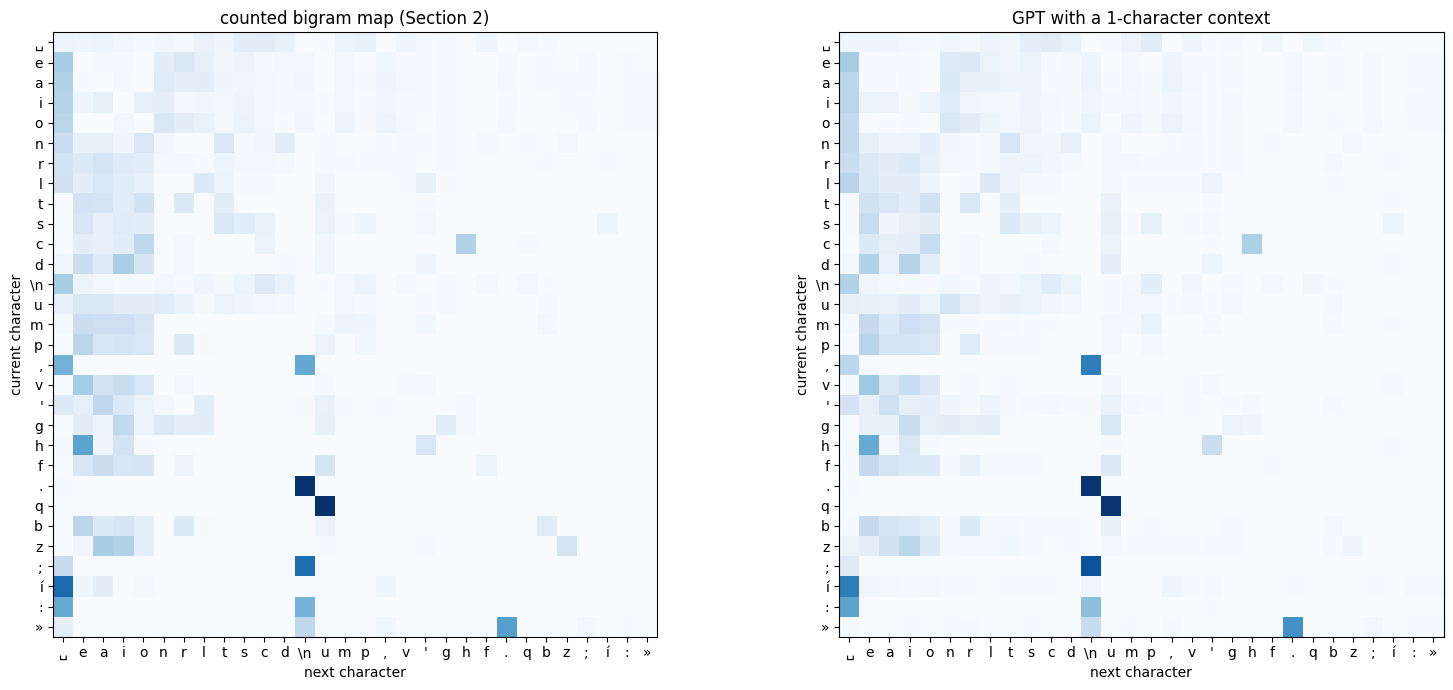

In [37]:
# ▶️ Given: the GPT's bigram map (one character in, next-character distribution out) vs the counted one
model.eval()
with torch.no_grad():
    one_char = torch.arange(vocab_size, device=device).unsqueeze(
        1
    )  # V windows of length 1
    P_gpt = (
        F.softmax(model(one_char)[0][:, 0, :], dim=-1).cpu().numpy()
    )  # (V, V): row c = P(next | c)

P_counts = np.zeros((vocab_size, vocab_size))
for a in range(vocab_size):
    c = bigram_table[(a,)]
    tot = sum(c.values())
    P_counts[a] = [
        (c[b] + 0.1) / (tot + 0.1 * vocab_size) for b in range(vocab_size)
    ]  # add-0.1, as in Section 4

freq = np.bincount(train_ids, minlength=vocab_size) / len(train_ids)
kl = float(np.sum(freq * np.sum(P_counts * np.log(P_counts / P_gpt), axis=1)))
print(f"average KL(counts || GPT) = {kl:.3f} nats")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, P, title in [
    (axes[0], P_counts, "counted bigram map (Section 2)"),
    (axes[1], P_gpt, "GPT with a 1-character context"),
]:
    ax.imshow(P[np.ix_(top, top)], cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(top)))
    ax.set_xticklabels(labels)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(labels)
    ax.set_xlabel("next character")
    ax.set_ylabel("current character")
    ax.set_title(title)
plt.tight_layout()
plt.show()

🤔 **Discuss.**

- Find a **previous-character head**. Which n-gram is it imitating? Why would the model need it, if the residual stream already contains the current character?
- Find a head that looks at **newlines** (or spaces). What can it compute from that? (Hint: how many characters ago was the last newline?)
- How do the heads of layer 1 differ from those of layer 0? Why can a head of layer 1 do things that no head of layer 0 can?
- The two bigram maps: where do they differ most, and why? Is the KL closer to 0 after 500 or after 5000 training steps?
- Attention weights tell us _where_ a head looks, not _why_. Can a high weight on a position be useless for the prediction? (Look at what the head does with the values.)


## 🔪 Exercise 2. Ablations: break the transformer, one piece at a time

An **ablation** removes one component and retrains the model, to measure what that component is for. It is the standard way of justifying an architecture in a paper. Here we train several variants of `TinyGPT` with the same data, the same batches and the same budget, and overlay their learning curves.

| variant                      | what is removed                                                                      |
| ---------------------------- | ------------------------------------------------------------------------------------ |
| `baseline`                   | nothing: the model of Section 7                                                      |
| `no position embeddings`     | $E_{pos}$ fixed at 0 (and not trained)                                               |
| `no residual connections`    | `x = attn(ln1(x))` instead of `x = x + attn(ln1(x))`, same for the feedforward layer |
| `no layer norm`              | `ln1`, `ln2` and `ln_f` replaced by the identity                                     |
| `no attention`               | every attention layer outputs 0                                                      |
| `no feedforward`             | every feedforward layer outputs 0                                                    |
| `no causal mask (cheating!)` | the mask is all ones: every position sees the whole window                           |

#### ✏️ What you have to write: `make_variant(name)`

- **Input:** one of the names in `VARIANTS`.
- **Output:** a fresh, untrained `TinyGPT` (built with `config`) on `device`, with the component removed.

The training is done by the given function `train_variant(m, steps)`: it trains `m` with AdamW, exactly as in Section 8, and returns its learning curve, a list of `(step, train_loss, val_loss)`.

> ⚙️ On CPU (300 steps per variant) the models are still far from converged and several curves overlap: the differences become clear with the GPU budget (1500 steps per variant, about 1 minute each on a T4).

> 💡 **Hints**
>
> - Build the baseline with `TinyGPT(config)`, then **modify it**: PyTorch modules are ordinary attributes, you can replace them (`blk.ln1 = nn.Identity()`), or change their tensors (`m.position_embedding.weight.data.zero_()`, then `.requires_grad_(False)` so that the optimizer leaves it at 0).
> - To remove the attention (or the feedforward layer) without touching `Block.forward`, replace it with a module whose `forward(x)` returns `torch.zeros_like(x)`: then `x + 0 = x`.
> - For the residual connections you need a different `forward`: write a subclass `class BlockNoResidual(Block)` that overrides it, and rebuild `m.blocks` with it (call `m.apply(m._init_weights)` again, so that it is initialized like the others).
> - The causal mask is the buffer `tril` of every `Head`: `head.tril.fill_(1.0)`.
> - Call `torch.manual_seed(SEED)` at the beginning of `make_variant`: all variants then start from the same random weights, as far as possible.

> 🎲 **Bet:** rank the variants from best to worst final validation loss. What will the loss of the "cheating" model be? And what kind of model is the transformer without attention? (Which loss from Section 4 will it reach?)


In [38]:
# ▶️ Given: the variants and the training helper used by the ablation
VARIANTS = [
    "baseline",
    "no position embeddings",
    "no residual connections",
    "no layer norm",
    "no attention",
    "no feedforward",
    "no causal mask (cheating!)",
]
ABLATION_STEPS = (
    1500 if device == "cuda" else 300
)  # per variant; on CPU the 7 variants take ≈ 7 minutes


@torch.no_grad()
def estimate_loss_of(m, eval_batches=10):
    m.eval()
    out = {}
    for split_name in ["train", "val"]:
        out[split_name] = (
            sum(m(*get_batch(split_name))[1].item() for _ in range(eval_batches))
            / eval_batches
        )
    m.train()
    return out


def train_variant(m, steps, lr=3e-4, n_evals=10):
    # Train m with AdamW as in Section 8; return [(step, train_loss, val_loss), ...]
    m = m.to(device)
    opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=lr)
    eval_every = max(steps // n_evals, 1)
    torch.manual_seed(SEED)  # the same batches for every variant
    hist = []
    m.train()
    for step in range(steps + 1):
        if step % eval_every == 0 or step == steps:
            l = estimate_loss_of(m)
            hist.append((step, l["train"], l["val"]))
        if step == steps:
            break
        xb, yb = get_batch("train")
        _, loss = m(xb, yb)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
    return hist

In [39]:
# ✏️ YOUR CODE HERE (Exercise 2)
def make_variant(name):
    """Input: one of the names in VARIANTS.
    Output: a fresh, untrained TinyGPT (built with config) on device, with the component removed."""
    torch.manual_seed(SEED)
    m = TinyGPT(config)
    # TODO: modify m according to name ("baseline" = no change)
    raise NotImplementedError("Exercise 2: make_variant")

The next cell trains every variant in `VARIANTS` (remove some names from the list if you are short of time), then overlays the validation curves (solid) and the training curves (dashed), with the uniform and best n-gram baselines. It also prints 150 generated characters from each model.


In [40]:
# ▶️ Given: train all the variants and overlay their learning curves
try:
    curves, samples = {}, {}
    for name in VARIANTS:
        t0 = time.perf_counter()
        m = make_variant(name)
        curves[name] = train_variant(m, ABLATION_STEPS)
        samples[name] = decode(
            m.generate(start, max_new_tokens=150, temperature=0.8, top_k=30)[0].tolist()
        )
        print(
            f"{name:28s} val loss {curves[name][-1][2]:.3f}   ({time.perf_counter() - t0:.0f} s)"
        )

    plt.figure(figsize=(10, 6))
    for i, (name, h) in enumerate(curves.items()):
        color = f"C{i}"
        plt.plot(
            [r[0] for r in h], [r[2] for r in h], marker="o", color=color, label=name
        )
        plt.plot(
            [r[0] for r in h], [r[1] for r in h], linestyle="--", color=color, alpha=0.5
        )
    plt.axhline(uniform_ce, color="gray", linestyle=":", label="uniform")
    plt.axhline(
        best_row["val_CE"],
        color="black",
        linestyle=":",
        label=f"best n-gram (n={int(best_row['order'])})",
    )
    for n, ls in [(2, "-."), (3, "--")]:
        plt.axhline(
            results_df[
                (results_df.order == n) & (results_df.alpha == 0.1)
            ].val_CE.item(),
            color="black",
            linestyle=ls,
            linewidth=0.8,
            label=f"{n}-gram",
        )
    plt.xlabel("training step")
    plt.ylabel("cross-entropy (nats / character)")
    plt.title(
        f"Ablations: validation (solid) and training (dashed), {ABLATION_STEPS} steps each"
    )
    plt.legend(fontsize=8)
    plt.show()

    for name, s in samples.items():
        print(f"\n===== {name} =====\n{s}")
except (NotImplementedError, NameError, TypeError, AttributeError) as e:
    print(f"⏳ write make_variant first ({type(e).__name__}: {e})")

⏳ write make_variant first (NotImplementedError: Exercise 2: make_variant)


🤔 **Discuss.**

- Which component matters most for this small model? Was your ranking right?
- The model without attention reaches almost exactly the loss of one of the n-gram models of Section 4. Which one, and why? (What can a position see, if the tokens never mix?)
- Without the causal mask the loss is spectacular. Look at its generated text: what happened?
- Without position embeddings the model is worse, but far from useless. Where does it still get information about order? (Hint: the causal mask. Which positions can the first character see? And the tenth?)
- Residual connections and layer norm matter more and more as models get **deeper**. Why? Try the ablation with `n_layer = 6`.


## ⚡ Exercise 3. Make the tiny GPT fast

The GPT implementation above was deliberately written to make the architecture of a Transformer easy to read: the attention mechanism builds the heads one by one, and `generate()` calls the whole model again for every generated token. This is how the slides explain it, but it is not how an efficient GPT implementation is written.

In this exercise you will progressively optimise the model while keeping its **mathematical behaviour unchanged**: same function, same outputs (up to floating-point noise), less time and memory. Three ideas used in every modern Transformer implementation:

|     | Part                               | You will learn                                                                              |
| --- | ---------------------------------- | ------------------------------------------------------------------------------------------- |
| 1   | Vectorise multi-head attention     | all the heads with one matrix product: the matrix form of SLP §7.3, with one more dimension |
| 2   | Use PyTorch's optimised attention  | fused attention kernels (FlashAttention) and the $T^2$ memory of attention                  |
| 3   | Find the waste in generation       | why `generate()` gets slower and slower                                                     |
| 4   | Implement a KV cache               | the KV cache of SLP §7.8                                                                    |
| 5   | _(optional)_ Preallocate the cache | a smaller engineering refinement                                                            |

After each part, the **▶️ Given** cell compares your implementation with the original one (the largest difference between the outputs must be tiny, around $10^{-6}$) and **plots time and memory**, so that you see what each step buys. On CPU some results can surprise you, and that is part of the lesson: in performance engineering, _measure, do not assume_.


In [41]:
# ▶️ Given: helpers used by the benchmark cells of the exercise (just run it)
def time_fn(fn, repeats=5):
    # average wall-clock time of fn() in seconds, after one warm-up call
    fn()
    if device == "cuda":
        torch.cuda.synchronize()  # GPU calls are asynchronous: wait for them to finish
    t0 = time.perf_counter()
    for _ in range(repeats):
        fn()
    if device == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / repeats


@torch.no_grad()
def copy_mha_into_csa(csa, mha):
    # Copy the weights of an original MultiHeadAttention into a CausalSelfAttention:
    # the q (then k, then v) weights of the A heads are stacked in the rows of csa.qkv.weight
    Wq = torch.cat([h.query.weight for h in mha.heads], dim=0)
    Wk = torch.cat([h.key.weight for h in mha.heads], dim=0)
    Wv = torch.cat([h.value.weight for h in mha.heads], dim=0)
    csa.qkv.weight.copy_(torch.cat([Wq, Wk, Wv], dim=0))
    if csa.qkv.bias is not None:
        csa.qkv.bias.zero_()
    csa.proj.load_state_dict(mha.proj.state_dict())


@torch.no_grad()
def fastgpt_from_tinygpt(fast, slow):
    # Copy all the weights of a TinyGPT into a FastGPT (same names, except the attention)
    fast.token_embedding.load_state_dict(slow.token_embedding.state_dict())
    fast.position_embedding.load_state_dict(slow.position_embedding.state_dict())
    fast.ln_f.load_state_dict(slow.ln_f.state_dict())
    fast.lm_head.load_state_dict(slow.lm_head.state_dict())
    for bf, bs in zip(fast.blocks, slow.blocks):
        bf.ln1.load_state_dict(bs.ln1.state_dict())
        bf.ln2.load_state_dict(bs.ln2.state_dict())
        bf.ffwd.load_state_dict(bs.ffwd.state_dict())
        copy_mha_into_csa(bf.attn, bs.attn)
    return fast


# A bigger configuration for the benchmarks: longer context, so that the effects are visible
bench_config = GPTConfig(
    vocab_size=vocab_size, block_size=512, n_embd=128, n_head=4, n_layer=4, dropout=0.0
)
print("Benchmark configuration:", bench_config)

Benchmark configuration: GPTConfig(vocab_size=77, block_size=512, n_embd=128, n_head=4, n_layer=4, dropout=0.0)


### ⚡ Part 1: vectorise multi-head attention

Inspect the `Head` and `MultiHeadAttention` classes. The current implementation creates several independent attention heads and evaluates them one after the other in a Python loop:

```python
x = torch.cat([head(x) for head in self.heads], dim=-1)
```

This follows the mathematical description of multi-head attention closely, but it launches many small separate operations. Replace `Head` and `MultiHeadAttention` with a single `CausalSelfAttention` module that computes **all the heads simultaneously**.

Instead of giving every head separate query, key and value projections, create a single projection

```python
self.qkv = nn.Linear(n_embd, 3 * n_embd, bias=False)
```

and split its output into queries, keys and values:

```python
q, k, v = self.qkv(x).chunk(3, dim=-1)        # each [B, T, d]
```

The first `head_dim` channels of `q` are the query of head 1, the next `head_dim` those of head 2, and so on. Reshape the three tensors so that the heads become a **batch dimension**:

```text
q, k, v : (batch, n_head, sequence, head_dim)        head_dim = n_embd // n_head
```

Then compute causal scaled dot-product attention for all the heads at once: `q @ k.transpose(-2, -1)` now gives a `(B, A, T, T)` tensor of scores, one $T \times T$ matrix per head. Finally merge the heads back into `(B, T, n_embd)`, which is the concatenation of their outputs, and apply $W^O$.

#### ✏️ What you have to write: `CausalSelfAttention(config, use_sdpa=False)`

- **Attributes** (already in the skeleton, keep the names: the benchmark copies the weights of the original module into them): `self.qkv`, `self.proj`, `self.n_head`, `self.tril`.
- **`forward(x, past_kv=None)`**
  - **Input:** `x` of shape `(B, T, n_embd)`. Ignore `past_kv` until Part 4.
  - **Output:** a tuple `(y, (k, v))`: `y` of shape `(B, T, n_embd)`, exactly like `MultiHeadAttention(x)`; `k` and `v` of shape `(B, n_head, T, head_dim)` (they will become the KV cache in Part 4).
- Leave the `use_sdpa=True` branch for Part 2.

> 💡 **Hints**
>
> - Reshape with `q.view(B, T, self.n_head, head_dim).transpose(1, 2)`; same for `k` and `v`.
> - The mask is the same as in `Head`: `self.tril[:T, :T] == 0` broadcasts over the batch and head dimensions.
> - Merge the heads with `y.transpose(1, 2).contiguous().view(B, T, C)`: `.contiguous()` is needed because `transpose` does not move the data in memory.
> - Do not forget the dropout on the attention weights and after `self.proj`, as in the original.

**Question:** why is one large matrix multiplication generally preferable to a Python loop over many smaller ones?

> 🎲 **Bet:** how much faster will your version be, for a context of 64 characters? And of 512?


In [42]:
# ✏️ YOUR CODE HERE (Parts 1, 2 and later 4)
class CausalSelfAttention(nn.Module):
    def __init__(self, config, use_sdpa=False):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.n_head = config.n_head
        self.use_sdpa = use_sdpa
        self.qkv = nn.Linear(
            config.n_embd, 3 * config.n_embd, bias=False
        )  # W^Q, W^K, W^V of all the heads
        self.proj = nn.Linear(config.n_embd, config.n_embd)  # W^O
        self.dropout_p = config.dropout
        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)
        self.register_buffer(
            "tril", torch.tril(torch.ones(config.block_size, config.block_size))
        )

    def forward(self, x, past_kv=None):
        # Input: x (B, T, n_embd). Output: (y, (k, v)) with y (B, T, n_embd), k and v (B, n_head, T, head_dim)
        B, T, C = x.shape
        # TODO (Part 1): q, k, v = ...  then reshape each to (B, n_head, T, head_dim)
        # TODO (Part 4): if past_kv is not None, concatenate the past keys/values along dim=2
        if self.use_sdpa:
            pass  # TODO (Part 2): y = F.scaled_dot_product_attention(...)
        else:
            pass  # TODO (Part 1): scores, mask, softmax, dropout, weighted sum of the values
        # TODO (Part 1): merge the heads back to (B, T, C), apply self.proj and self.resid_dropout
        raise NotImplementedError("Exercise, Part 1")
        # return y, (k, v)

The next cell copies the weights of a random `MultiHeadAttention` into your module, checks that the two give the same output, and measures the time of a **forward + backward** pass (one training step of the attention layer) for contexts of growing length $T$.


⏳ vectorised (Part 1): not implemented yet (NotImplementedError: Exercise, Part 1)
⏳ SDPA (Part 2): not implemented yet (NotImplementedError: Exercise, Part 1)


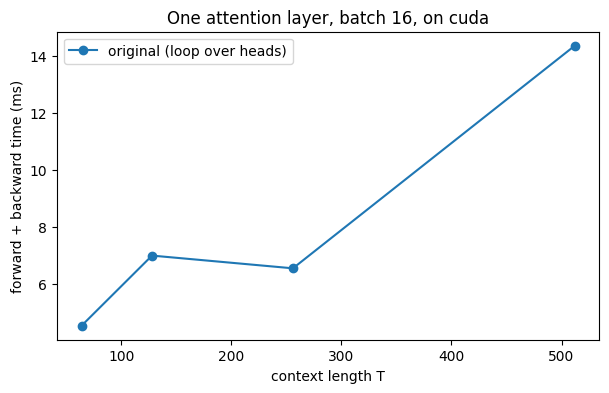

,original (loop over heads)
T,
64,4.5
128,7.0
256,6.6
512,14.4


In [43]:
# ▶️ Given: benchmark of Parts 1 and 2 (≈ 30 s on CPU)
SEQ_LENS = [64, 128, 256, 512]
BENCH_BATCH = 16


def attention_versions():
    # the original module and your versions, all with the same weights
    torch.manual_seed(0)
    mha = MultiHeadAttention(bench_config).to(device).eval()
    versions = {"original (loop over heads)": lambda x: mha(x)}
    for use_sdpa, name in [(False, "vectorised (Part 1)"), (True, "SDPA (Part 2)")]:
        try:
            csa = CausalSelfAttention(bench_config, use_sdpa=use_sdpa).to(device).eval()
            copy_mha_into_csa(csa, mha)
            x = torch.randn(2, 32, bench_config.n_embd, device=device)
            with torch.no_grad():
                y, _ = csa(x)
                diff = (y - mha(x)).abs().max().item()
            print(f"{name:28s} max |difference| from the original: {diff:.1e}")
            versions[name] = lambda x, m=csa: m(x)[0]
        except (
            NotImplementedError,
            NameError,
        ) as e:  # NameError: e.g. the use_sdpa branch is still empty
            print(f"⏳ {name}: not implemented yet ({type(e).__name__}: {e})")
    return versions


versions = attention_versions()
timings = {name: [] for name in versions}
for T in SEQ_LENS:
    x = torch.randn(
        BENCH_BATCH, T, bench_config.n_embd, device=device, requires_grad=True
    )
    for name, f in versions.items():
        timings[name].append(1000 * time_fn(lambda: f(x).sum().backward(), repeats=3))

plt.figure(figsize=(7, 4))
for name, ts in timings.items():
    plt.plot(SEQ_LENS, ts, marker="o", label=name)
plt.xlabel("context length T")
plt.ylabel("forward + backward time (ms)")
plt.title(f"One attention layer, batch {BENCH_BATCH}, on {device}")
plt.legend()
plt.show()
pd.DataFrame(timings, index=pd.Index(SEQ_LENS, name="T")).round(1)

### 🚀 Part 2: use PyTorch's optimised attention

Your vectorised implementation still computes attention explicitly:

```python
scores = q @ k.transpose(-2, -1) / math.sqrt(head_dim)
scores = scores.masked_fill(mask == 0, float("-inf"))
weights = F.softmax(scores, dim=-1)
y = weights @ v
```

This creates an intermediate attention matrix whose size grows **quadratically** with the sequence length, `(batch, n_head, sequence, sequence)`: the _cost of attention_ slide of Lecture 14. During training it must even be kept in memory for the backward pass.

Replace this calculation with

```python
F.scaled_dot_product_attention(q, k, v, is_causal=True)
```

PyTorch then uses a **fused** kernel when the hardware, data type and tensor layout allow it. Implementations based on **FlashAttention** never materialise the complete attention matrix: they evaluate attention block by block, keeping only the running maximum and sum needed by the softmax. The mathematical operation is still

$$
\operatorname{Attention}(Q,K,V) = \operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V,
$$

but the computation is organised to avoid expensive transfers to and from the GPU memory.

#### ✏️ What you have to write

Fill the `use_sdpa` branch of your `CausalSelfAttention` (in the cell of Part 1) and re-run it.

> 💡 **Hints**
>
> - `F.scaled_dot_product_attention` already applies the scaling $1/\sqrt{d_k}$ and the softmax; it returns `(B, A, T, head_dim)`, exactly like `weights @ v`.
> - Pass `dropout_p=self.dropout_p if self.training else 0.0`: the function does not know whether the module is in training mode.
> - `is_causal=True` is right _here_, because queries and keys have the same length. Remember this sentence in Part 4.

**Question:** for a sequence of length $T$, how many elements does the attention matrix of a single head contain? What happens when $T$ is doubled? With $T$ = 100,000 tokens and 32 heads, how many GB would one layer need in float32?

Re-run the benchmark cell of Part 1 to add the SDPA curve to the time plot. The next cell looks at **memory**.


⏳ vectorised (Part 1): not implemented yet (NotImplementedError: Exercise, Part 1)
⏳ SDPA (Part 2): not implemented yet (NotImplementedError: Exercise, Part 1)


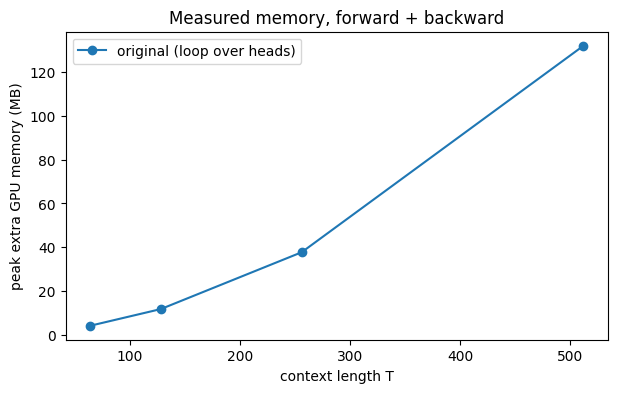

In [44]:
# ▶️ Given: memory of one attention layer (forward + backward)
plt.figure(figsize=(7, 4))
if device == "cuda":
    versions = attention_versions()
    for name, f in versions.items():
        peaks = []
        for T in SEQ_LENS:
            x = torch.randn(
                BENCH_BATCH, T, bench_config.n_embd, device=device, requires_grad=True
            )
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()
            base = torch.cuda.memory_allocated()
            f(x).sum().backward()
            torch.cuda.synchronize()
            peaks.append((torch.cuda.max_memory_allocated() - base) / 2**20)
        plt.plot(SEQ_LENS, peaks, marker="o", label=name)
    plt.ylabel("peak extra GPU memory (MB)")
    plt.title("Measured memory, forward + backward")
else:
    # On CPU PyTorch does not report allocations: we plot the size of what the explicit version must store
    A = bench_config.n_head
    sizes = [
        2 * BENCH_BATCH * A * T * T * 4 / 2**20 for T in SEQ_LENS
    ]  # scores + softmax weights, float32
    plt.plot(
        SEQ_LENS, sizes, marker="o", label="explicit attention: B·A·T² scores + weights"
    )
    plt.ylabel("MB")
    plt.title("Theoretical memory of the T×T matrices (CPU: not measured)")
    print("Run on a GPU runtime to measure the real memory of the three versions.")
plt.xlabel("context length T")
plt.legend()
plt.show()

### 🔍 Part 3: find the waste in autoregressive generation

Now inspect the model's `generate()` method. Suppose the current sequence is

```text
Nel mezzo del cammin di nostra
```

and the model generates ` vita`. To predict the following character, the current implementation runs the **whole model again** on

```text
Nel mezzo del cammin di nostra vita
```

Consequently, the keys and values of `Nel mezzo del cammin di nostra` are computed again (in every layer!), even though they were already computed at the previous generation step. Repeat this reasoning for several generated tokens.

**Question:** if the prompt contains $T$ tokens, which computations are repeated when generating the next token? How does the total work grow with the number of generated tokens?

The next cell needs no code from you: it times every single step of the original generation loop on the bigger benchmark model (random weights: we only care about the time).


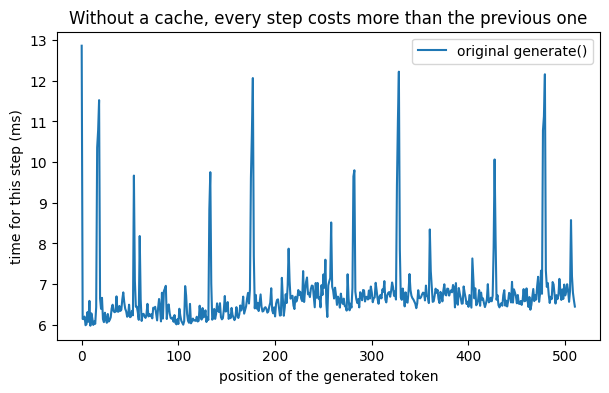

total time for 511 tokens: 3.45 s


In [45]:
# ▶️ Given: time of each generation step with the original generate() (≈ 10 s on CPU)
@torch.no_grad()
def step_times_original(m, n_new):
    # the loop of TinyGPT.generate (greedy), timing each step
    m.eval()
    idx = torch.zeros((1, 1), dtype=torch.long, device=device)
    times = []
    for _ in range(n_new):
        t0 = time.perf_counter()
        logits, _ = m(idx[:, -m.config.block_size :])  # the whole context, again
        nxt = logits[:, -1, :].argmax(dim=-1, keepdim=True)
        idx = torch.cat([idx, nxt], dim=1)
        if device == "cuda":
            torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return np.array(times)


torch.manual_seed(0)
big_slow = TinyGPT(bench_config).to(device).eval()
N_NEW = bench_config.block_size - 1
t_orig = step_times_original(big_slow, N_NEW)

plt.figure(figsize=(7, 4))
plt.plot(1000 * t_orig, label="original generate()")
plt.xlabel("position of the generated token")
plt.ylabel("time for this step (ms)")
plt.title("Without a cache, every step costs more than the previous one")
plt.legend()
plt.show()
print(f"total time for {N_NEW} tokens: {t_orig.sum():.2f} s")

### 🗄️ Part 4: implement a KV cache

This is the **KV cache** of SLP §7.8: store the keys and values of the previous tokens, and for a new token compute only its own query, key and value. In the figure of the book, the black vectors come from the cache; only $q_4$, $k_4$ and $v_4$ are new:

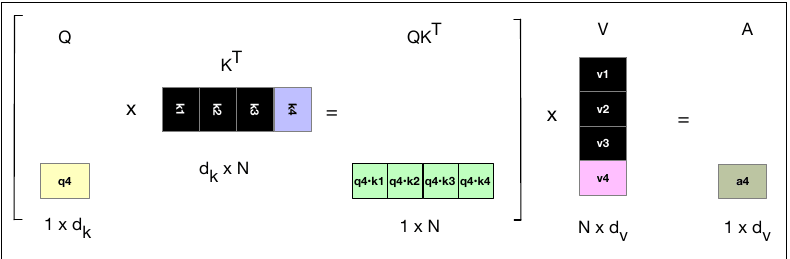

When processing the prompt, compute $Q, K, V$ normally and **keep $K$ and $V$**. For each following decoding step, pass **only the newly generated token** through the model, compute $q_{new}, k_{new}, v_{new}$, and append the new key and value to those of the previous steps:

```python
k = torch.cat([past_k, k_new], dim=2)
v = torch.cat([past_v, v_new], dim=2)
```

Every layer has its own cache, of shape `(batch, n_head, cached_sequence_length, head_dim)`.

Queries do **not** need to be cached: the new token needs its own query, compared with the keys of all the previous tokens.

#### ✏️ What you have to write

1. In your `CausalSelfAttention.forward` (Part 1 cell), the `past_kv` branch: if `past_kv = (past_k, past_v)` is given, concatenate before computing attention, and return the concatenated `(k, v)`.
2. `FastBlock(config, use_sdpa=False)`: like `Block`, but `forward(x, past_kv=None)` returns `(x, new_kv)`.
3. `FastGPT(config, use_sdpa=False)`: like `TinyGPT`, with the **same attribute names** (`token_embedding`, `position_embedding`, `blocks`, `ln_f`, `lm_head`: the benchmark copies the trained weights of `model` into it), and
   - `forward(idx, targets=None, past_kvs=None, pos_offset=0)` → `(logits, loss, new_kvs)`: `past_kvs` is the list of the caches of the $L$ layers; `pos_offset` is the position of the first token of `idx`;
   - `generate_cached(idx, max_new_tokens, temperature=1.0, top_k=None)` → like `TinyGPT.generate`: run the prompt once, then feed **one token per step** with the cache.

> 💡 **Hints**
>
> - **Positions:** the new token at step $t$ is not at position 0! Use `torch.arange(pos_offset, pos_offset + T)`.
> - **Mask:** with a cache, the $T$ new queries are the **last** $T$ of the $T_{total}$ keys, so the mask is the last $T$ rows of the causal mask: `self.tril[T_total - T:T_total, :T_total]`. For a single new token, it is a row of ones: the new token sees everything.
> - **SDPA:** `is_causal=True` with `T_q ≠ T_k` aligns the mask to the _top-left_ corner, which is wrong here: pass the mask above as `attn_mask` (as booleans) instead.
> - Use `nn.ModuleList` for the blocks (`nn.Sequential` cannot pass the caches along).
> - **No sliding window:** with a cache, prompt + generated tokens must fit in `block_size`.
> - To compare with the original, use greedy decoding: `top_k=1` makes `generate` deterministic.

**Question:** why do we cache $K$ and $V$, but normally not $Q$? How much memory does the cache of a model with $L$ layers, $d$ = `n_embd` and context $N$ need, per sequence?


In [46]:
# ✏️ YOUR CODE HERE (Part 4)
class FastBlock(nn.Module):
    def __init__(self, config, use_sdpa=False):
        super().__init__()
        self.ln1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config, use_sdpa)
        self.ln2 = nn.LayerNorm(config.n_embd)
        self.ffwd = FeedForward(config)

    def forward(self, x, past_kv=None):
        # Output: (x, new_kv). TODO: as Block.forward, passing past_kv to the attention
        raise NotImplementedError("Exercise, Part 4")


class FastGPT(nn.Module):
    def __init__(self, config, use_sdpa=False):
        super().__init__()
        self.config = config
        self.token_embedding = nn.Embedding(config.vocab_size, config.n_embd)
        self.position_embedding = nn.Embedding(config.block_size, config.n_embd)
        self.blocks = nn.ModuleList([
            FastBlock(config, use_sdpa) for _ in range(config.n_layer)
        ])
        self.ln_f = nn.LayerNorm(config.n_embd)
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size)

    def forward(self, idx, targets=None, past_kvs=None, pos_offset=0):
        # Output: (logits, loss, new_kvs). TODO: as TinyGPT.forward, with positions starting at pos_offset,
        # and each block receiving and returning its own cache
        raise NotImplementedError("Exercise, Part 4")

    @torch.no_grad()
    def generate_cached(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        # TODO: process the prompt once, then ONE new token per step, passing the caches along
        raise NotImplementedError("Exercise, Part 4")

The next cell first checks that your `FastGPT`, with the **trained** weights of `model`, generates exactly the same greedy text as `model.generate`. Then it times every generation step on the bigger benchmark model, as in Part 3, now with your cache.


In [47]:
# ▶️ Given: KV cache, correctness and time per step (≈ 15 s on CPU)
@torch.no_grad()
def step_times_cached(fast, n_new):
    # the loop of generate_cached (greedy), timing each step; uses only FastGPT.forward
    fast.eval()
    idx = torch.zeros((1, 1), dtype=torch.long, device=device)
    logits, _, kvs = fast(idx)
    times = []
    for _ in range(n_new):
        t0 = time.perf_counter()
        nxt = logits[:, -1, :].argmax(dim=-1, keepdim=True)
        idx = torch.cat([idx, nxt], dim=1)
        logits, _, kvs = fast(
            nxt, past_kvs=kvs, pos_offset=idx.size(1) - 1
        )  # one token in, one step
        if device == "cuda":
            torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return np.array(times)


try:
    # 1. correctness with the trained weights
    fast = fastgpt_from_tinygpt(FastGPT(config).to(device), model).eval()
    prompt = val_tensor[:10].unsqueeze(0).to(device)
    n_new = config.block_size - prompt.size(1)
    same = torch.equal(
        model.generate(prompt, n_new, top_k=1),
        fast.generate_cached(prompt, n_new, top_k=1),
    )
    print("Greedy text identical to model.generate:", same)
    print(repr(decode(fast.generate_cached(prompt, n_new, top_k=1)[0].tolist())))

    # 2. time per step on the big model, same weights as big_slow
    big_fast = fastgpt_from_tinygpt(
        FastGPT(bench_config, use_sdpa=True).to(device), big_slow
    ).eval()
    t_cache = step_times_cached(big_fast, N_NEW)

    plt.figure(figsize=(7, 4))
    plt.plot(1000 * t_orig, label=f"original generate()  total {t_orig.sum():.2f} s")
    plt.plot(1000 * t_cache, label=f"KV cache (Part 4)   total {t_cache.sum():.2f} s")
    plt.xlabel("position of the generated token")
    plt.ylabel("time for this step (ms)")
    plt.title(f"Speed-up ×{t_orig.sum() / t_cache.sum():.1f} for {N_NEW} tokens")
    plt.legend()
    plt.show()
except (NotImplementedError, NameError) as e:
    print(f"⏳ not implemented yet ({type(e).__name__}: {e})")

⏳ not implemented yet (NotImplementedError: Exercise, Part 4)


### 🧰 Part 5 (optional): preallocate the cache

Your cache works, but every

```python
k = torch.cat([past_k, k_new], dim=2)
```

allocates a new tensor and **copies the whole cache** so far: at step $t$ we copy $t$ keys and $t$ values in every layer. As a refinement, allocate the cache **once**, with room for `block_size` positions, and write each new key and value in place:

```python
k_cache[:, :, position:position+1, :] = k_new
v_cache[:, :, position:position+1, :] = v_new
```

then attend to `k_cache[:, :, :position+1]`. Each layer needs its own pair of buffers.

How much does it buy? Much less than Part 4. In our CPU tests (4 layers, 511 tokens) the preallocated cache was only about **1.1–1.3× faster** than `torch.cat` for one sequence, and about 1.8× for a batch of 8: a real gain, but small next to the ×10 or more of the cache itself. In production, preallocation matters also for other reasons: no memory fragmentation, and tensors of fixed shape, which compilers and CUDA graphs need.

#### ✏️ What you have to write

A method `FastGPT.generate_preallocated(idx, max_new_tokens, temperature=1.0, top_k=None)`, with the same behaviour as `generate_cached`.

> 💡 **Hints**
>
> - Allocate, for each layer, `torch.empty(B, n_head, block_size, head_dim, device=...)` for the keys and for the values.
> - Add arguments `cache=None, pos=0` to `CausalSelfAttention.forward`, `FastBlock.forward` and `FastGPT.forward` (e.g. `caches=` for the list of the $L$ buffers), and write the new keys/values at positions `pos:pos+T`.
> - The mask is the same as in Part 4, with $T_{total}$ = `pos + T`.


In [48]:
# ✏️ YOUR CODE HERE (Part 5, optional)
@torch.no_grad()
def generate_preallocated(self, idx, max_new_tokens, temperature=1.0, top_k=None):
    # TODO: allocate one (k, v) pair of buffers per layer, then generate as in generate_cached
    raise NotImplementedError("Exercise, Part 5")


FastGPT.generate_preallocated = generate_preallocated  # attach the method to the class

In [49]:
# ▶️ Given: torch.cat cache vs preallocated cache (≈ 10 s on CPU)
GEN_BATCH = (
    1  # try 8: the more data the cache holds, the more the copies of torch.cat cost
)

try:
    p0 = torch.zeros((GEN_BATCH, 1), dtype=torch.long, device=device)
    same = torch.equal(
        big_fast.generate_cached(p0, N_NEW, top_k=1),
        big_fast.generate_preallocated(p0, N_NEW, top_k=1),
    )
    print("Same text as generate_cached:", same)
    totals = {
        "original generate()": time_fn(
            lambda: big_slow.generate(p0, N_NEW, top_k=1), repeats=1
        ),
        "KV cache, torch.cat": time_fn(
            lambda: big_fast.generate_cached(p0, N_NEW, top_k=1), repeats=2
        ),
        "KV cache, preallocated": time_fn(
            lambda: big_fast.generate_preallocated(p0, N_NEW, top_k=1), repeats=2
        ),
    }
    plt.figure(figsize=(7, 3.5))
    bars = plt.barh(list(totals), list(totals.values()))
    plt.bar_label(bars, labels=[f"{v:.2f} s" for v in totals.values()])
    plt.xlabel(f"time to generate {N_NEW} tokens, batch {GEN_BATCH} (s)")
    plt.gca().invert_yaxis()
    plt.show()
except (NotImplementedError, NameError) as e:
    print(f"⏳ not implemented yet ({e})")

⏳ not implemented yet (name 'big_fast' is not defined)


🤔 **Discuss.**

- Which of the five parts gave the largest gain in **training**? And in **generation**? Why are they different?
- The KV cache trades memory for time. For a model like Llama 3.1 8B (L = 32 layers, d = 4096; it actually uses _grouped-query attention_, which shrinks the cache by 4×) and a context of 128k tokens, estimate the size of the cache without GQA, in float16.
- `generate()` crops the context to `block_size` (a sliding window), while the cached version stops at `block_size`. Why can't we simply drop the oldest entry of the cache and continue? (Think about the position embeddings.)
